<a href="https://colab.research.google.com/github/yasuoThongThao7/QuanNet/blob/main/Hybrid_DehazeCNN_Kiet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmark kiểu bài báo DehazeNet + ablation cho Hybrid DCP-CNN

Notebook này **nối tiếp** notebook huấn luyện của bạn (`hybrid_best.pth` trong `Checkpoints_Dehaze_v2`) và tạo ra các số liệu, biểu đồ **cùng dạng với bài báo DehazeNet** (Cai et al., IEEE TIP 2016) để so sánh được, đồng thời đáp ứng các nhận xét phản biện.

| Mục trong bài DehazeNet | Notebook này tạo ra | File xuất ra (`benchmark_v1/`) |
|---|---|---|
| Hình 6 (Maxout / ReLU / Linear ở tầng 1) | đường hội tụ val t-MSE của 3 biến thể DehazeNet-FC | `fig_convergence.png` |
| Hình 7 (BReLU / ReLU / Sigmoid ở tầng cuối) | đường hội tụ của 3 biến thể | `fig_convergence.png` |
| Hình 8 (dự đoán so với t thật) | scatter + đường trung bình theo bin | `fig_scatter_t.png` |
| Bảng II (số bộ lọc / kích thước) | ablation: số tham số, MSE huấn luyện, MSE kiểm tra | `table2_ablation.csv` |
| Bảng III (MSE t trên patch 16×16, α=1) | tái hiện đúng protocol patch của bài báo | `table3_patch_protocol.csv` |
| Bảng IV (MSE/SSIM/PSNR/WSNR trên ảnh tổng hợp) | ITS-test, SOTS-indoor, SOTS-outdoor (+ O-HAZE nếu có) | `table4_images.csv` |
| Bảng V (CRE/ARE/SRE/NRE) | độ bền theo độ dày sương, ánh sáng khí quyển, tỉ lệ ảnh, nhiễu | `table5_robustness.csv`, `fig_robustness.png` |
| Hình 9/12 (ảnh trước-sau) | cùng vùng cắt phóng to, có chú thích PSNR/SSIM | `fig_qualitative_*.png` |

**Thêm so với bài báo (theo yêu cầu phản biện):** ablation zero-init / residual / dilation / GF / đặc trưng DCP, baseline học sâu nhẹ cùng dữ liệu (DehazeNet-FC, AOD-Net), khoảng tin cậy theo cảnh, phân tích vùng sáng/trời, đo thời gian từng khâu, đối soát t-MSE, thống kê dữ liệu, danh sách train/val.

**Cách dùng:** `Runtime → GPU`, sửa các đường dẫn ở ô *Cấu hình*, chạy từ trên xuống. Mỗi lần huấn luyện biến thể được lưu vào `benchmark_v1/runs/`; nếu phiên bị ngắt, chạy lại là **tự bỏ qua các biến thể đã xong**.

In [2]:
import os, sys, re, time, json, math, random, zipfile, copy, subprocess
import numpy as np, pandas as pd, cv2
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm
try:
    from pytorch_msssim import ssim as ssim_torch
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'pytorch-msssim'], check=True)
    from pytorch_msssim import ssim as ssim_torch
from skimage.metrics import peak_signal_noise_ratio as psnr_fn, structural_similarity as ssim_fn
from skimage.color import rgb2lab, deltaE_ciede2000
try:
    from IPython.display import display
except ImportError:
    display = print

cv2.setNumThreads(0)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = False
print('device:', device, '| torch', torch.__version__)

Mounted at /content/drive
device: cpu | torch 2.11.0+cpu


## 1. Cấu hình

In [ ]:
# ===== ĐƯỜNG DẪN (giữ giống notebook huấn luyện) =====
ZIP_PATH  = '/content/drive/MyDrive/RESIDE.zip'
DATA_DIR  = '/content/dataset'
CKPT_DIR  = '/content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2'
MAIN_CKPT = os.path.join(CKPT_DIR, 'hybrid_best.pth')         # mô hình chính đã huấn luyện 30 epoch
BENCH_DIR = os.path.join(CKPT_DIR, 'benchmark_v1')            # nơi lưu mọi kết quả của notebook này

# Dữ liệu sương thật (tùy chọn, để None nếu chưa có)
OHAZE_HAZY, OHAZE_GT = None, None        # ví dụ '/content/O-HAZE/hazy', '/content/O-HAZE/GT'
REAL_DIR = None                          # thư mục ảnh sương thật bất kỳ (không cần GT) chỉ để vẽ minh họa

# ===== CHIA DỮ LIỆU (phải trùng notebook huấn luyện) =====
SEED = 42
MIN_VAL_SCENES = 20      # notebook huấn luyện: n_val = max(20, 5% số cảnh)
N_SEL_SCENES = 20        # trong các cảnh val: dùng để CHỌN checkpoint cho các ablation; phần còn lại là TEST sạch

# ===== NGÂN SÁCH HUẤN LUYỆN CHO ABLATION / BASELINE =====
N_CACHE = 1500           # số ảnh ITS-train nạp vào RAM (~2.3 GB với 1500 ảnh) để huấn luyện ablation nhanh
PATCH, BATCH_IMGS, CROPS, M = 256, 8, 4, 8
LR = 1e-3
EPOCHS_ABL, ITERS_ABL = 12, 300        # mỗi biến thể ablation: 12 x 300 = 3.600 iteration
RUN_LONG_BASELINES = True              # huấn luyện thêm DehazeNet-FC và AOD-Net với ngân sách bằng mô hình chính
EPOCHS_MAIN, ITERS_MAIN = 30, 500      # = 30 epoch x 500 iter, đúng bằng notebook huấn luyện (4000 ảnh / 8)

# ===== ĐÁNH GIÁ =====
N_TEST_IMGS = 300        # ảnh ITS-test dùng cho bảng ảnh (None = toàn bộ)
N_SOTS = None            # None = toàn bộ 500 ảnh mỗi tập SOTS
N_PATCH_IMG = 2000       # số patch 16x16 (x10 giá trị t) cho protocol Bảng III của bài báo (2.000 x 10 = 20.000)
N_ROBUST = None          # số cảnh dùng cho Bảng V (None = tất cả cảnh test)
GF_R, GF_EPS, T_MIN = 20, 1e-3, 0.1

## 2. Dữ liệu: ghép cặp, chia theo cảnh, xuất danh sách train/val, thống kê

Phần này **sao đúng logic** của notebook huấn luyện (cùng quy tắc ghép cặp, cùng seed, cùng cách chia 5% cảnh) nên `val_items` trùng tuyệt đối. Thêm: kiểm tra không rò rỉ cảnh, xuất danh sách mẫu ra CSV, thống kê mức sương.

In [ ]:
os.makedirs(BENCH_DIR, exist_ok=True)
RUNS_DIR = os.path.join(BENCH_DIR, 'runs'); os.makedirs(RUNS_DIR, exist_ok=True)
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()

IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')
def find_its_root():
    for r, dirs, _ in os.walk(DATA_DIR):
        if {'hazy', 'trans', 'clear'} <= set(dirs):
            return r
    return None

ITS_ROOT = find_its_root() if os.path.isdir(DATA_DIR) else None
if ITS_ROOT is None:
    print('Chưa thấy ITS, đang giải nén phần cần thiết từ zip...')
    with zipfile.ZipFile(ZIP_PATH) as z:
        members = [m for m in z.namelist() if ('archive(1)' in m.split('/')) or ('SOTS' in m.split('/'))]
        assert members, 'Không có file nào dưới archive(1)/ hoặc SOTS/ trong zip: cấu trúc zip khác, hãy giải nén tay vào DATA_DIR'
        z.extractall(DATA_DIR, members)
    ITS_ROOT = find_its_root()
assert ITS_ROOT, 'Không tìm thấy thư mục chứa đủ hazy/trans/clear'
print('ITS_ROOT =', ITS_ROOT)

SOTS_DIRS = {}
for r, dirs, _ in os.walk(DATA_DIR):
    if 'sots' in r.lower() and 'hazy' in dirs and ({'gt', 'clear'} & set(dirs)):
        g = 'gt' if 'gt' in dirs else 'clear'
        name = 'indoor' if 'indoor' in r.lower() else ('outdoor' if 'outdoor' in r.lower() else os.path.basename(r))
        SOTS_DIRS[name] = (os.path.join(r, 'hazy'), os.path.join(r, g))
for k, v in SOTS_DIRS.items(): print('SOTS', k, '->', v)

def index_dir(d):
    return {os.path.splitext(f)[0]: os.path.join(d, f) for f in os.listdir(d) if f.lower().endswith(IMG_EXT)}

def load_rgb(p, hw=None):
    img = cv2.imread(p, cv2.IMREAD_COLOR)
    assert img is not None, f'không đọc được ảnh: {p}'
    img = np.ascontiguousarray(img[..., ::-1])
    if hw is not None and img.shape[:2] != tuple(hw):
        img = cv2.resize(img, (hw[1], hw[0]), interpolation=cv2.INTER_AREA)
    return img

def load_rgb_max(p, max_side=None):
    img = load_rgb(p)
    if max_side and max(img.shape[:2]) > max_side:
        s = max_side / max(img.shape[:2])
        img = cv2.resize(img, (int(img.shape[1] * s), int(img.shape[0] * s)), interpolation=cv2.INTER_AREA)
    return img

def load_trans(p, hw=None):
    raw = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    assert raw is not None, f'không đọc được trans: {p}'
    if raw.ndim == 3: raw = raw[..., 0]
    t = raw.astype(np.float32) / (65535. if raw.dtype == np.uint16 else 255.)
    if hw is not None and t.shape != tuple(hw):
        t = cv2.resize(t, (hw[1], hw[0]), interpolation=cv2.INTER_LINEAR)
    return t

def build_its(root):
    hz, tr, cl = (index_dir(os.path.join(root, s)) for s in ('hazy', 'trans', 'clear'))
    items, missing = [], 0
    for stem, p in sorted(hz.items()):
        parts = stem.split('_'); sid = parts[0]; tkey = '_'.join(parts[:2])
        try: A = float(parts[2]) if len(parts) >= 3 else None
        except ValueError: A = None
        cands = [tkey, stem, tkey + '_trans', sid + '_trans', sid]
        rule = next((i for i, c in enumerate(cands) if c in tr), None)
        cp = cl.get(sid) or cl.get(stem)
        if rule is None or cp is None:
            missing += 1; continue
        items.append(dict(hazy=p, trans=tr[cands[rule]], clear=cp, id=sid, k=parts[1] if len(parts) > 1 else '', A=A))
    print('ITS ghép được:', len(items), '| thiếu:', missing)
    if len(items) < 0.99 * len(hz):
        raise RuntimeError('Ghép cặp thất bại (>1% thiếu).')
    return items

its_items = build_its(ITS_ROOT)
ids = sorted({it['id'] for it in its_items})
random.Random(SEED).shuffle(ids)
n_val = max(MIN_VAL_SCENES, int(0.05 * len(ids)))
val_ids = set(ids[:n_val])
train_items = [it for it in its_items if it['id'] not in val_ids]
val_items = [it for it in its_items if it['id'] in val_ids]

# TEST sạch: các cảnh val KHÔNG dùng để chọn checkpoint của ablation
val_scene_list = sorted(val_ids); random.Random(SEED + 1).shuffle(val_scene_list)
sel_scenes = set(val_scene_list[:N_SEL_SCENES])
sel_items = [it for it in val_items if it['id'] in sel_scenes]
test_items = [it for it in val_items if it['id'] not in sel_scenes]
assert not ({it['id'] for it in train_items} & val_ids), 'RÒ RỈ: cảnh train trùng cảnh val'
assert not ({it['id'] for it in sel_items} & {it['id'] for it in test_items}), 'RÒ RỈ: cảnh chọn trùng cảnh test'
print(f'train {len(train_items)} mẫu / {len({i["id"] for i in train_items})} cảnh | val {len(val_items)} mẫu / {len(val_ids)} cảnh '
      f'(chọn-checkpoint {len(sel_items)} mẫu / {len(sel_scenes)} cảnh, TEST sạch {len(test_items)} mẫu / {len({i["id"] for i in test_items})} cảnh)')

ITS_ROOT = /content/dataset/archive(1)
SOTS outdoor -> ('/content/dataset/SOTS/SOTS/outdoor/hazy', '/content/dataset/SOTS/SOTS/outdoor/gt')
SOTS indoor -> ('/content/dataset/SOTS/SOTS/indoor/hazy', '/content/dataset/SOTS/SOTS/indoor/gt')
ITS ghép được: 13990 | thiếu: 0
train 13300 mẫu / 1330 cảnh | val 690 mẫu / 69 cảnh (chọn-checkpoint 200 mẫu / 20 cảnh, TEST sạch 490 mẫu / 49 cảnh)


đã lưu danh sách mẫu: /content/drive/MyDrive/Dehaze_Project/Checkpoints_Dehaze_v2/benchmark_v1/sample_lists.csv (13990 dòng)
t_tb_mau = trung bình bản đồ truyền dẫn t trên mẫu 600 ảnh (t thấp = sương dày). Biến thể mức sương/cảnh:


,split,mau,canh,mau_moi_canh,A_tb,A_std,t_tb_mau,t_std_mau,t_p10,t_p90
0,train,13300,1330,10.0,0.8507,0.0864,0.5371,0.1268,0.3698,0.7022
1,val_select,200,20,10.0,0.8452,0.0862,0.5275,0.1253,0.3633,0.6787
2,val_test,490,49,10.0,0.8522,0.0872,0.5515,0.1233,0.3786,0.7123


phân bố biến thể (k) trong train: {'1': 1330, '10': 1330, '2': 1330, '3': 1330, '4': 1330, '5': 1330, '6': 1330, '7': 1330, '8': 1330, '9': 1330}


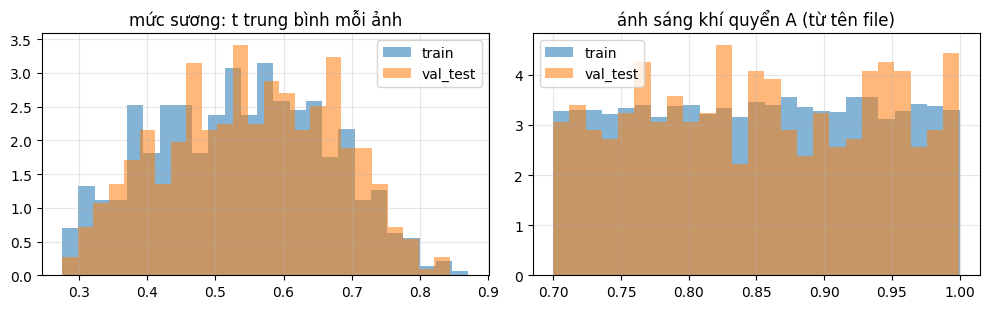

In [ ]:
# ---------- Danh sách mẫu + thống kê mức sương (công bố cùng bài) ----------
def to_df(items, split):
    return pd.DataFrame([dict(split=split, scene=it['id'], variant=it['k'], A_from_name=it['A'],
                              hazy=os.path.basename(it['hazy']), trans=os.path.basename(it['trans']), clear=os.path.basename(it['clear'])) for it in items])
lists = pd.concat([to_df(train_items, 'train'), to_df(sel_items, 'val_select'), to_df(test_items, 'val_test')])
lists.to_csv(os.path.join(BENCH_DIR, 'sample_lists.csv'), index=False)
print('đã lưu danh sách mẫu:', os.path.join(BENCH_DIR, 'sample_lists.csv'), f'({len(lists)} dòng)')

def tmean_sample(items, n=600, seed=0):
    sub = random.Random(seed).sample(items, min(n, len(items)))
    return np.array([load_trans(it['trans']).mean() for it in sub])

rows = []
for name, its in (('train', train_items), ('val_select', sel_items), ('val_test', test_items)):
    d = to_df(its, name); tm = tmean_sample(its)
    per_scene = d.groupby('scene').size()
    rows.append(dict(split=name, mau=len(d), canh=d.scene.nunique(), mau_moi_canh=per_scene.mean(),
                     A_tb=d.A_from_name.astype(float).mean(), A_std=d.A_from_name.astype(float).std(),
                     t_tb_mau=tm.mean(), t_std_mau=tm.std(), t_p10=np.percentile(tm, 10), t_p90=np.percentile(tm, 90)))
data_stats = pd.DataFrame(rows).round(4)
data_stats.to_csv(os.path.join(BENCH_DIR, 'data_stats.csv'), index=False)
print('t_tb_mau = trung bình bản đồ truyền dẫn t trên mẫu 600 ảnh (t thấp = sương dày). Biến thể mức sương/cảnh:')
display(data_stats)
print('phân bố biến thể (k) trong train:', lists[lists.split == 'train'].variant.value_counts().sort_index().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for nm, its in (('train', train_items), ('val_test', test_items)):
    ax[0].hist(tmean_sample(its), bins=25, alpha=.55, label=nm, density=True)
    ax[1].hist([i['A'] for i in its if i['A'] is not None], bins=25, alpha=.55, label=nm, density=True)
ax[0].set_title('mức sương: t trung bình mỗi ảnh'); ax[1].set_title('ánh sáng khí quyển A (từ tên file)')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(BENCH_DIR, 'fig_data_distribution.png'), dpi=160); plt.show()

## 3. Lõi: DCP trên GPU, guided filter, khôi phục, chỉ số (thêm MSE và WSNR như Bảng IV của bài báo)

In [ ]:
def estimate_A_np(img_u8, scale=0.25, k=5, percent=0.1):
    small = cv2.resize(img_u8, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.
    dark = cv2.erode(small.min(2), np.ones((k, k), np.uint8))
    n = max(int(dark.size * percent / 100), 1)
    idx = np.argpartition(dark.ravel(), -n)[-n:]
    return small.reshape(-1, 3)[idx].mean(0).astype(np.float32)

def min_filter(x, k=15):
    return -F.max_pool2d(-x, k, stride=1, padding=k // 2)

def dcp_inputs(x, A, omega=0.95, k=15):
    dark = min_filter(x.min(1, keepdim=True)[0], k)
    dark_n = min_filter((x / A.clamp_min(1e-3)).min(1, keepdim=True)[0], k)
    return dark, (1 - omega * dark_n).clamp(0, 1)

def make_input_t(kind, hz_u8, A):
    x = hz_u8.float() / 255.
    if kind == 'rgb': return x
    dark, tr = dcp_inputs(x, A.view(-1, 3, 1, 1))
    return torch.cat([x, dark, tr], 1)

def sync():
    if device.type == 'cuda': torch.cuda.synchronize()

def box(x, r):
    return cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1), borderType=cv2.BORDER_REFLECT)

def guided_filter(I, p, r, eps):
    mI, mp = box(I, r), box(p, r)
    cov, var = box(I * p, r) - mI * mp, box(I * I, r) - mI * mI
    a = cov / (var + eps); b = mp - a * mI
    return box(a, r) * I + box(b, r)

def recover(img, t, A, t_min=0.1):
    t = np.clip(t, t_min, 1.0)[..., None]
    return np.clip((img - A) / t + A, 0, 1)

# ---- WSNR (CSF Mannos-Sakrison, trọng số tần số) - xấp xỉ chỉ số WSNR của bài báo; giả định 32 pixel/độ ----
_csf_cache = {}
def _csf(shape, ppd=32.0):
    if shape not in _csf_cache:
        fy = np.fft.fftfreq(shape[0])[:, None]; fx = np.fft.fftfreq(shape[1])[None, :]
        f = np.sqrt(fx ** 2 + fy ** 2) * ppd
        H = 2.6 * (0.0192 + 0.114 * f) * np.exp(-(0.114 * f) ** 1.1)
        H[0, 0] = 0.0
        _csf_cache[shape] = H
    return _csf_cache[shape]

def wsnr(ref, dist):
    y = lambda a: (0.299 * a[..., 0] + 0.587 * a[..., 1] + 0.114 * a[..., 2]) * 255.
    r, d = y(ref), y(dist); H = _csf(r.shape)
    num = np.sum(np.abs(np.fft.fft2(r) * H) ** 2); den = np.sum(np.abs(np.fft.fft2(r - d) * H) ** 2) + 1e-12
    return float(10 * np.log10(num / den + 1e-12))

def img_metrics(pred, gt, full=True):
    mse = float(np.mean((pred - gt) ** 2))
    out = dict(MSE=mse, PSNR=min(float(psnr_fn(gt, pred, data_range=1.0)), 100.0),
               SSIM=float(ssim_fn(gt, pred, channel_axis=2, data_range=1.0)))
    if full:
        out['CIEDE2000'] = float(deltaE_ciede2000(rgb2lab(gt), rgb2lab(pred)).mean())
        out['WSNR'] = wsnr(gt, pred)
    return out

def bright_mask(gt):
    # vùng sáng mạnh / gần như không màu (xấp xỉ trời, đèn, vật trắng): độ chói > 0.85 và độ bão hòa < 0.15
    lum = 0.299 * gt[..., 0] + 0.587 * gt[..., 1] + 0.114 * gt[..., 2]
    mx, mn = gt.max(2), gt.min(2)
    return (lum > 0.85) & ((mx - mn) / (mx + 1e-6) < 0.15)

def loss_fn(pred, gt):
    mse = F.mse_loss(pred, gt)
    return mse + 0.1 * (1.0 - ssim_torch(pred, gt, data_range=1.0, size_average=True)), mse

## 4. Các mô hình

- **HybridVar**: mô hình của bạn, tham số hóa để làm ablation. Cấu hình mặc định (`ch=32`, dilation `(1,2,4)`, residual, zero-init) cho **cùng tên tham số** với `HybridTransmissionCNN` nên nạp được `hybrid_best.pth`.
- **DehazeNet-FC**: đúng Bảng I của bài báo (conv 5×5 → Maxout k=4 → đa tỉ lệ 3/5/7 → max-pool 7×7 → conv 6×6 → BReLU), chạy toàn ảnh; có biến thể tầng 1 (`maxout`/`relu`/`linear`) và tầng cuối (`brelu`/`relu`/`sigmoid`) như Hình 6, 7.
- **AOD-Net** (Li et al., ICCV 2017): baseline học sâu nhẹ khác (1.761 tham số), học trực tiếp ảnh sạch.

In [ ]:
class HybridVar(nn.Module):
    def __init__(self, in_ch=5, ch=32, dil=(1, 2, 4), residual=True, zero_init=True, final='clamp'):
        super().__init__()
        layers, c = [], in_ch
        for d in dil:
            layers += [nn.Conv2d(c, ch, 3, padding=d, dilation=d), nn.PReLU(ch)]; c = ch
        layers += [nn.Conv2d(c, 1, 3, padding=1)]
        self.body = nn.Sequential(*layers)
        self.residual, self.final = residual, final
        if zero_init:
            nn.init.zeros_(self.body[-1].weight); nn.init.zeros_(self.body[-1].bias)
    def forward(self, x):
        z = self.body(x)
        t = (x[:, 4:5] + z) if self.residual else z
        if self.final == 'sigmoid':
            return torch.sigmoid(t)
        t_hard = t.clamp(0., 1.)
        if not self.training:
            return t_hard
        return t + (t_hard - t).detach()           # straight-through: giá trị = t_hard, gradient luôn thông

class DehazeNetFC(nn.Module):
    def __init__(self, f1='maxout', f4='brelu'):
        super().__init__()
        self.f1, self.f4 = f1, f4
        self.c1 = nn.Conv2d(3, 16, 5, padding=2)
        if f1 in ('relu', 'linear'):
            self.low = nn.Conv2d(16, 4, 1)                         # ánh xạ tuyến tính 16 -> 4 (16x1x1) như Hình 6
        self.c2a, self.c2b, self.c2c = nn.Conv2d(4, 16, 3, padding=1), nn.Conv2d(4, 16, 5, padding=2), nn.Conv2d(4, 16, 7, padding=3)
        self.pool = nn.MaxPool2d(7, stride=1, padding=3)
        self.c4 = nn.Conv2d(48, 1, 6)
        for m in (self.c1, self.c2a, self.c2b, self.c2c, self.c4):
            nn.init.normal_(m.weight, 0, 0.001); nn.init.zeros_(m.bias)   # khởi tạo Gaussian sigma=0.001 như bài báo
        if f4 != 'sigmoid':
            nn.init.constant_(self.c4.bias, 0.5)                   # lệch khởi tạo (bài báo dùng 0) để tránh chết gradient lúc đầu
    def forward(self, x):
        x = self.c1(x)
        if self.f1 == 'maxout':
            B, _, H, W = x.shape
            x = x.view(B, 4, 4, H, W).max(dim=2)[0]
        elif self.f1 == 'relu':
            x = self.low(F.relu(x))
        else:
            x = self.low(x)
        x = self.pool(torch.cat([self.c2a(x), self.c2b(x), self.c2c(x)], 1))
        x = self.c4(F.pad(x, (2, 3, 2, 3)))
        if self.f4 == 'brelu': return x.clamp(0., 1.)               # BReLU nguyên bản (gradient = 0 ngoài [0,1])
        if self.f4 == 'relu': return F.relu(x)
        return torch.sigmoid(x)

class AODNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(3, 3, 1), nn.Conv2d(3, 3, 3, padding=1)
        self.c3, self.c4 = nn.Conv2d(6, 3, 5, padding=2), nn.Conv2d(6, 3, 7, padding=3)
        self.c5 = nn.Conv2d(12, 3, 3, padding=1)
    def forward(self, x):
        x1 = F.relu(self.c1(x)); x2 = F.relu(self.c2(x1))
        x3 = F.relu(self.c3(torch.cat([x1, x2], 1))); x4 = F.relu(self.c4(torch.cat([x2, x3], 1)))
        k = F.relu(self.c5(torch.cat([x1, x2, x3, x4], 1)))
        return F.relu(k * x - k + 1.0)                              # J = K*I - K + b, b = 1

def n_params(m): return sum(p.numel() for p in m.parameters())
for nm, m in (('HybridVar (mặc định)', HybridVar()), ('DehazeNet-FC', DehazeNetFC()), ('AOD-Net', AODNet())):
    w = sum(p.numel() for n_, p in m.named_parameters() if 'weight' in n_ and 'prelu' not in n_.lower())
    print(f'{nm:<22} tham số: {n_params(m):>7,}')
print('Bài báo ghi DehazeNet có 8.240 tham số (chỉ tính trọng số, không tính bias) và AOD-Net gốc 1.761.')

HybridVar (mặc định)   tham số:  20,353
DehazeNet-FC           tham số:   8,305
AOD-Net                tham số:   1,761
Bài báo ghi DehazeNet có 8.240 tham số (chỉ tính trọng số, không tính bias) và AOD-Net gốc 1.761.


## 5. Nạp mô hình chính và **kiểm tra bắt buộc** (tránh lặp lại lỗi "đánh giá bằng mô hình chưa học")

Lần đánh giá trước cho kết quả Hybrid+GF **giống hệt** DCP+GF ở từng ảnh, vì ô đánh giá chạy khi `model` còn là bản khởi tạo (lớp cuối bằng 0 → đầu ra bằng DCP). Ô dưới đây nạp `hybrid_best.pth` và **dừng ngay** nếu mô hình vẫn trùng DCP.

In [ ]:
@torch.no_grad()
def predict_t(model, img_u8, A, kind='hybrid', dev=None):
    dev = dev or device
    x = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1)[None].to(dev).float() / 255.
    if kind == 'rgb':
        inp = x
    else:
        dark, tr = dcp_inputs(x, torch.from_numpy(A).to(dev).view(1, 3, 1, 1))
        inp = torch.cat([x, dark, tr], 1)
    model.eval()
    return model(inp)[0, 0].float().cpu().numpy()

@torch.no_grad()
def dcp_t(img_u8, A, win=15, omega=0.95, dev=None):
    dev = dev or device
    x = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1)[None].to(dev).float() / 255.
    return dcp_inputs(x, torch.from_numpy(A).to(dev).view(1, 3, 1, 1), omega, win)[1][0, 0].float().cpu().numpy()

@torch.no_grad()
def predict_aod(model, img_u8, dev=None):
    dev = dev or device
    x = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1)[None].to(dev).float() / 255.
    model.eval()
    return model(x)[0].clamp(0, 1).permute(1, 2, 0).float().cpu().numpy()

def build_cache(items, n=None, seed=0, desc='cache'):
    sub = items if n is None else random.Random(seed).sample(items, min(n, len(items)))
    out = []
    for it in tqdm(sub, desc=desc, leave=False):
        img = load_rgb(it['hazy'])
        out.append(dict(img=img, A=estimate_A_np(img), tg=load_trans(it['trans'], img.shape[:2]),
                        clear=load_rgb(it['clear'], img.shape[:2]), it=it))
    return out

def eval_t_mse(model, kind, cache, gf=False):
    res = []
    for c in cache:
        t = predict_t(model, c['img'], c['A'], kind)
        if gf:
            g = cv2.cvtColor(c['img'].astype(np.float32) / 255., cv2.COLOR_RGB2GRAY)
            t = np.clip(guided_filter(g, t, GF_R, GF_EPS), 0, 1)
        res.append(((t - c['tg']) ** 2).mean())
    return float(np.mean(res))

def eval_t_mse_dcp(cache, win=15, omega=0.95):
    return float(np.mean([((dcp_t(c['img'], c['A'], win, omega) - c['tg']) ** 2).mean() for c in cache]))

abl_cache = build_cache(sel_items, 100, seed=0, desc='cache chọn-checkpoint (ablation)')
test_cache = build_cache(test_items, 150, seed=0, desc='cache TEST sạch')
dcp_sel, dcp_test = eval_t_mse_dcp(abl_cache), eval_t_mse_dcp(test_cache)
print(f't-MSE của DCP thuần | tập chọn {dcp_sel:.5f} | TEST sạch {dcp_test:.5f}')

assert os.path.exists(MAIN_CKPT), f'Không thấy checkpoint chính: {MAIN_CKPT}'
model_main = HybridVar().to(device)
sd = torch.load(MAIN_CKPT, map_location=device, weights_only=False)
if isinstance(sd, dict) and 'model' in sd: sd = sd['model']
model_main.load_state_dict(sd); model_main.eval()
w_last = model_main.body[-1].weight.abs().sum().item()
v_main, v_dcp = eval_t_mse(model_main, 'hybrid', test_cache), dcp_test
print(f'|w| lớp cuối = {w_last:.3f} (0 nghĩa là chưa học) | TEST sạch: Hybrid chính {v_main:.5f} so với DCP {v_dcp:.5f}')
assert w_last > 0 and abs(v_main - v_dcp) > 1e-4, 'MÔ HÌNH CHÍNH ĐANG TRÙNG DCP: checkpoint chưa nạp đúng, KHÔNG đánh giá tiếp!'

cache chọn-checkpoint (ablation):   0%|          | 0/100 [00:00<?, ?it/s]

cache TEST sạch:   0%|          | 0/150 [00:00<?, ?it/s]

t-MSE của DCP thuần | tập chọn 0.02879 | TEST sạch 0.02828
|w| lớp cuối = 5.390 (0 nghĩa là chưa học) | TEST sạch: Hybrid chính 0.01174 so với DCP 0.02828


## 6. Đối soát t-MSE: vì sao 0,00986 (log huấn luyện) khác 0,0112 / 0,0120 (bảng đánh giá)?

Con số 0,00986 là **giá trị nhỏ nhất trong 30 lần đo** trên **100 ảnh**, **t thô, không guided filter**; 0,0112 / 0,0120 đo trên **300 ảnh khác**, lần lượt **t thô** và **sau guided filter**. Ô dưới tính lại trên cùng một hệ quy chiếu để thấy từng nguyên nhân (chọn mẫu, lựa chọn checkpoint tốt nhất, guided filter, rò rỉ cảnh).

In [ ]:
def t_mse_stream(model, items, kind='hybrid', gf=False, dcp=False):
    res = []
    for it in tqdm(items, leave=False):
        img = load_rgb(it['hazy']); A = estimate_A_np(img); tg = load_trans(it['trans'], img.shape[:2])
        t = dcp_t(img, A) if dcp else predict_t(model, img, A, kind)
        if gf:
            g = cv2.cvtColor(img.astype(np.float32) / 255., cv2.COLOR_RGB2GRAY)
            t = np.clip(guided_filter(g, t, GF_R, GF_EPS), 0, 1)
        res.append(((t - tg) ** 2).mean())
    return float(np.mean(res))

orig_cache_items = random.Random(0).sample(val_items, min(100, len(val_items)))      # đúng tập 100 ảnh của vòng lặp huấn luyện
orig_eval_items = random.Random(1).sample(val_items, min(300, len(val_items)))       # đúng tập 300 ảnh của bảng đánh giá
oc = {it['hazy'] for it in orig_cache_items}
rest_items = [it for it in val_items if it['hazy'] not in oc]                        # ảnh val KHÔNG dùng để chọn checkpoint
recon = []
def add(label, items, **kw):
    recon.append(dict(thiet_lap=label, so_anh=len(items), t_MSE_Hybrid=t_mse_stream(model_main, items, **kw),
                      t_MSE_DCP=t_mse_stream(None, items, dcp=True, gf=kw.get('gf', False))))
add('A. 100 ảnh chọn checkpoint (train loop), t thô', orig_cache_items)
add('B. 300 ảnh của bảng đánh giá, t thô  ("Hybrid thô")', orig_eval_items)
add('C. 300 ảnh của bảng đánh giá, sau GF ("Hybrid+GF")', orig_eval_items, gf=True)
if rest_items:
    add('D. ảnh val KHÔNG dùng chọn checkpoint, t thô', rest_items[:300])
    add('E. ảnh val KHÔNG dùng chọn checkpoint, sau GF', rest_items[:300], gf=True)
recon = pd.DataFrame(recon); recon.to_csv(os.path.join(BENCH_DIR, 'recon_tmse.csv'), index=False)
display(recon.round(5))
print('giao nhau giữa 100 ảnh chọn và 300 ảnh đánh giá:', len(oc & {it['hazy'] for it in orig_eval_items}), 'ảnh')
hp = os.path.join(CKPT_DIR, 'train_history.csv')
if os.path.exists(hp):
    h = pd.read_csv(hp)
    print(f'\nLịch sử huấn luyện: giá trị nhỏ nhất = {h.val_t_mse.min():.5f} (epoch {int(h.epoch[h.val_t_mse.idxmin()])}); '
          f'trung bình 10 epoch cuối = {h.val_t_mse.tail(10).mean():.5f}; trung vị toàn bộ = {h.val_t_mse.median():.5f}')
    print('=> lấy MIN của 30 lần đo nhiễu trên 100 ảnh luôn lạc quan; hãy báo cáo số ở dòng D/E (hoặc SOTS), không dùng 0,00986.')

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

...

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/300 [00:00<?, ?it/s]

,thiet_lap,so_anh,t_MSE_Hybrid,t_MSE_DCP
0,"A. 100 ảnh chọn checkpoint (train loop), t thô",100,0.00986,0.02782
1,"B. 300 ảnh của bảng đánh giá, t thô (""Hybrid ...",300,0.01196,0.03075
2,"C. 300 ảnh của bảng đánh giá, sau GF (""Hybrid+...",300,0.01117,0.02732
3,"D. ảnh val KHÔNG dùng chọn checkpoint, t thô",300,0.00954,0.02548
4,"E. ảnh val KHÔNG dùng chọn checkpoint, sau GF",300,0.00884,0.02262


giao nhau giữa 100 ảnh chọn và 300 ảnh đánh giá: 34 ảnh

Lịch sử huấn luyện: giá trị nhỏ nhất = 0.00986 (epoch 19); trung bình 10 epoch cuối = 0.01013; trung vị toàn bộ = 0.01120
=> lấy MIN của 30 lần đo nhiễu trên 100 ảnh luôn lạc quan; hãy báo cáo số ở dòng D/E (hoặc SOTS), không dùng 0,00986.


## 7. Huấn luyện ablation và baseline cùng một ngân sách

Nạp `N_CACHE` ảnh ITS-train vào RAM một lần rồi cắt patch ngẫu nhiên trực tiếp từ RAM (không giải mã PNG mỗi iteration) nên mỗi biến thể chỉ mất vài phút. Biến thể đã có file trong `benchmark_v1/runs/` được **bỏ qua**.

| Nhóm | Biến thể | Câu hỏi trả lời |
|---|---|---|
| Hybrid | `hyb_full` | cấu hình đầy đủ (residual + zero-init + dilation + loss MSE+SSIM + đặc trưng DCP) |
| | `hyb_no_zero` | zero-init có cần không? |
| | `hyb_no_resid` | residual trên t thô có cần không? |
| | `hyb_no_dil` | dilation (vùng nhìn 17 px so với 9 px) có ích không? |
| | `hyb_mse_only` | số hạng SSIM trong loss có ích không? |
| | `cnn_rgb_only` | CNN cùng kiến trúc nhưng **không có đặc trưng DCP** |
| | `hyb_ch16`, `hyb_ch64` | độ rộng mạng (tương tự Bảng II) |
| DehazeNet-FC | `dn_maxout_brelu` | đúng cấu hình bài báo (baseline học sâu 1) |
| | `dn_relu_brelu`, `dn_linear_brelu` | Hình 6 |
| | `dn_maxout_relu`, `dn_maxout_sigmoid` | Hình 7 |
| AOD-Net | `aodnet` | baseline học sâu nhẹ 2 |
| Ngân sách dài | `dn_main`, `aod_main` | baseline với 15.000 iteration như mô hình chính (công bằng hơn) |

In [ ]:
class RamSet:
    def __init__(self, items, n, patch, seed=0):
        sel = random.Random(seed).sample(items, min(n, len(items)))
        self.hz, self.tr, self.cl, self.A, self.patch = [], [], [], [], patch
        for it in tqdm(sel, desc='nạp RAM'):
            img = load_rgb(it['hazy']); hw = img.shape[:2]
            t, cl = load_trans(it['trans'], hw), load_rgb(it['clear'], hw)
            if min(hw) < patch:
                s = patch / min(hw) + 1e-3; size = (int(math.ceil(hw[1] * s)), int(math.ceil(hw[0] * s)))
                img, cl = cv2.resize(img, size, interpolation=cv2.INTER_LINEAR), cv2.resize(cl, size, interpolation=cv2.INTER_LINEAR)
                t = cv2.resize(t, size, interpolation=cv2.INTER_LINEAR)
            self.hz.append(img); self.cl.append(cl); self.tr.append(t.astype(np.float16)); self.A.append(estimate_A_np(img))
    def batch(self, B, K, rng):
        P, hz, tr, cl, A = self.patch, [], [], [], []
        for i in rng.choice(len(self.hz), size=min(B, len(self.hz)), replace=False):
            H, W = self.tr[i].shape
            for _ in range(K):
                y, x = int(rng.integers(0, H - P + 1)), int(rng.integers(0, W - P + 1))
                a, b, c = self.hz[i][y:y + P, x:x + P], self.tr[i][y:y + P, x:x + P], self.cl[i][y:y + P, x:x + P]
                if rng.random() < 0.5: a, b, c = a[:, ::-1], b[:, ::-1], c[:, ::-1]
                hz.append(np.ascontiguousarray(a)); tr.append(np.ascontiguousarray(b)); cl.append(np.ascontiguousarray(c)); A.append(self.A[i])
        st = lambda z: torch.from_numpy(np.stack(z))
        return st(hz).permute(0, 3, 1, 2).contiguous(), st(tr).float()[:, None], st(cl).permute(0, 3, 1, 2).contiguous(), st(A)

ram = RamSet(train_items, N_CACHE, PATCH)

def val_metric(model, kind):
    if kind == 'aod':
        return float(np.mean([np.mean((predict_aod(model, c['img']) - c['clear'].astype(np.float32) / 255.) ** 2) for c in abl_cache]))
    return eval_t_mse(model, kind, abl_cache)

def train_variant(name, spec, epochs, iters, force=False):
    jp, pp = os.path.join(RUNS_DIR, name + '.json'), os.path.join(RUNS_DIR, name + '.pt')
    model = spec['build']().to(device)
    if os.path.exists(jp) and os.path.exists(pp) and not force:
        model.load_state_dict(torch.load(pp, map_location=device)); model.eval()
        print(f'[{name}] đã có kết quả -> bỏ qua huấn luyện'); return model, json.load(open(jp))
    seed_all(SEED); rng = np.random.default_rng(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=spec.get('lr', LR))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * iters, eta_min=1e-5)
    hist, best, best_sd = [], 1e9, None
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = runm = 0.
        for _ in range(iters):
            hz, tg, cl, A = (z.to(device) for z in ram.batch(BATCH_IMGS, CROPS, rng))
            if spec['kind'] == 'aod':
                pred = model(hz.float() / 255.); y = cl.float() / 255.
                loss = mse = F.mse_loss(pred[..., M:-M, M:-M], y[..., M:-M, M:-M])
            else:
                with torch.no_grad(): inp = make_input_t(spec['kind'], hz, A)
                pred = model(inp); p, g = pred[..., M:-M, M:-M], tg[..., M:-M, M:-M]
                if spec.get('loss', 'mse_ssim') == 'mse': loss = mse = F.mse_loss(p, g)
                else: loss, mse = loss_fn(p, g)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            run += loss.item(); runm += mse.item()
        v = val_metric(model, spec['kind']); model.train()
        hist.append(dict(epoch=ep + 1, train_loss=run / iters, train_mse=runm / iters, val=v, sec=time.time() - t0))
        if v < best: best, best_sd = v, copy.deepcopy(model.state_dict())
        print(f'[{name}] epoch {ep + 1:2d}/{epochs} train MSE {runm / iters:.5f} | val {v:.5f} | {time.time() - t0:.0f}s')
    model.load_state_dict(best_sd); model.eval()
    torch.save(best_sd, pp)
    json.dump(dict(name=name, params=n_params(model), epochs=epochs, iters=iters, hist=hist), open(jp, 'w'), indent=1)
    return model, json.load(open(jp))

VARIANTS = {
    'hyb_full':        dict(kind='hybrid', build=lambda: HybridVar()),
    'hyb_no_zero':     dict(kind='hybrid', build=lambda: HybridVar(zero_init=False)),
    'hyb_no_resid':    dict(kind='hybrid', build=lambda: HybridVar(residual=False, zero_init=False)),
    'hyb_no_dil':      dict(kind='hybrid', build=lambda: HybridVar(dil=(1, 1, 1))),
    'hyb_mse_only':    dict(kind='hybrid', build=lambda: HybridVar(), loss='mse'),
    'cnn_rgb_only':    dict(kind='rgb',    build=lambda: HybridVar(in_ch=3, residual=False, zero_init=False)),
    'hyb_ch16':        dict(kind='hybrid', build=lambda: HybridVar(ch=16)),
    'hyb_ch64':        dict(kind='hybrid', build=lambda: HybridVar(ch=64)),
    'dn_maxout_brelu':  dict(kind='rgb', build=lambda: DehazeNetFC('maxout', 'brelu'), loss='mse'),
    'dn_relu_brelu':    dict(kind='rgb', build=lambda: DehazeNetFC('relu', 'brelu'), loss='mse'),
    'dn_linear_brelu':  dict(kind='rgb', build=lambda: DehazeNetFC('linear', 'brelu'), loss='mse'),
    'dn_maxout_relu':   dict(kind='rgb', build=lambda: DehazeNetFC('maxout', 'relu'), loss='mse'),
    'dn_maxout_sigmoid': dict(kind='rgb', build=lambda: DehazeNetFC('maxout', 'sigmoid'), loss='mse'),
    'aodnet':          dict(kind='aod', build=lambda: AODNet(), lr=5e-4),
}
if RUN_LONG_BASELINES:
    VARIANTS['dn_main'] = dict(kind='rgb', build=lambda: DehazeNetFC('maxout', 'brelu'), loss='mse', epochs=EPOCHS_MAIN, iters=ITERS_MAIN)
    VARIANTS['aod_main'] = dict(kind='aod', build=lambda: AODNet(), lr=5e-4, epochs=EPOCHS_MAIN, iters=ITERS_MAIN)

models, hists = {}, {}
for name, spec in VARIANTS.items():
    models[name], hists[name] = train_variant(name, spec, spec.get('epochs', EPOCHS_ABL), spec.get('iters', ITERS_ABL))
print('\nhoàn tất', len(models), 'biến thể')

nạp RAM:   0%|          | 0/1500 [00:00<?, ?it/s]

[hyb_full] đã có kết quả -> bỏ qua huấn luyện
[hyb_no_zero] đã có kết quả -> bỏ qua huấn luyện
[hyb_no_resid] đã có kết quả -> bỏ qua huấn luyện
[hyb_no_dil] đã có kết quả -> bỏ qua huấn luyện
[hyb_mse_only] đã có kết quả -> bỏ qua huấn luyện
[cnn_rgb_only] đã có kết quả -> bỏ qua huấn luyện
[hyb_ch16] đã có kết quả -> bỏ qua huấn luyện
[hyb_ch64] đã có kết quả -> bỏ qua huấn luyện
[dn_maxout_brelu] đã có kết quả -> bỏ qua huấn luyện
[dn_relu_brelu] đã có kết quả -> bỏ qua huấn luyện
[dn_linear_brelu] đã có kết quả -> bỏ qua huấn luyện
[dn_maxout_relu] đã có kết quả -> bỏ qua huấn luyện
[dn_maxout_sigmoid] đã có kết quả -> bỏ qua huấn luyện
[aodnet] đã có kết quả -> bỏ qua huấn luyện
[dn_main] epoch  1/30 train MSE 0.02217 | val 0.01905 | 181s
[dn_main] epoch  2/30 train MSE 0.02028 | val 0.01797 | 179s
[dn_main] epoch  3/30 train MSE 0.01927 | val 0.01733 | 179s
[dn_main] epoch  4/30 train MSE 0.01876 | val 0.01736 | 180s
[dn_main] epoch  5/30 train MSE 0.01833 | val 0.01811 | 179s
[d

## 8. Bảng II (ablation / số tham số) và Hình 6, 7 (đường hội tụ)

,bien_the,mo_ta,tham_so,iter,train_MSE_cuoi,val_chon_tot_nhat,test_t_MSE,so_voi_hyb_full_%
0,hyb_full,Hybrid đầy đủ,20353,3600,0.01170,0.01129,0.01253,0.00000
1,hyb_no_zero,bỏ zero-init,20353,3600,0.01170,0.01146,0.01277,1.92952
2,hyb_no_resid,bỏ residual (dự đoán t trực tiếp),20353,3600,0.01215,0.01236,0.01402,11.89163
3,hyb_no_dil,"bỏ dilation (1,1,1)",20353,3600,0.01247,0.01169,0.01285,2.54877
4,hyb_mse_only,loss chỉ MSE,20353,3600,0.01118,0.01098,0.01230,-1.84144
5,cnn_rgb_only,CNN thuần RGB (không DCP),19777,3600,0.01398,0.01271,0.01632,30.27692
6,hyb_ch16,độ rộng 16,5569,3600,0.01209,0.01180,0.01283,2.45164
7,hyb_ch64,độ rộng 64,77569,3600,0.01118,0.01045,0.01192,-4.84033
8,dn_maxout_brelu,DehazeNet-FC (Maxout+BReLU),8305,3600,0.01779,0.01682,0.01959,56.36622
9,dn_relu_brelu,DehazeNet-FC (ReLU+BReLU),8373,3600,0.01745,0.01639,0.01890,50.88645


Bảng II của bài báo (để đối chiếu xu hướng): DehazeNet 8.240 tham số -> test MSE 1,190e-2; tăng số bộ lọc thì MSE giảm nhưng tham số tăng.


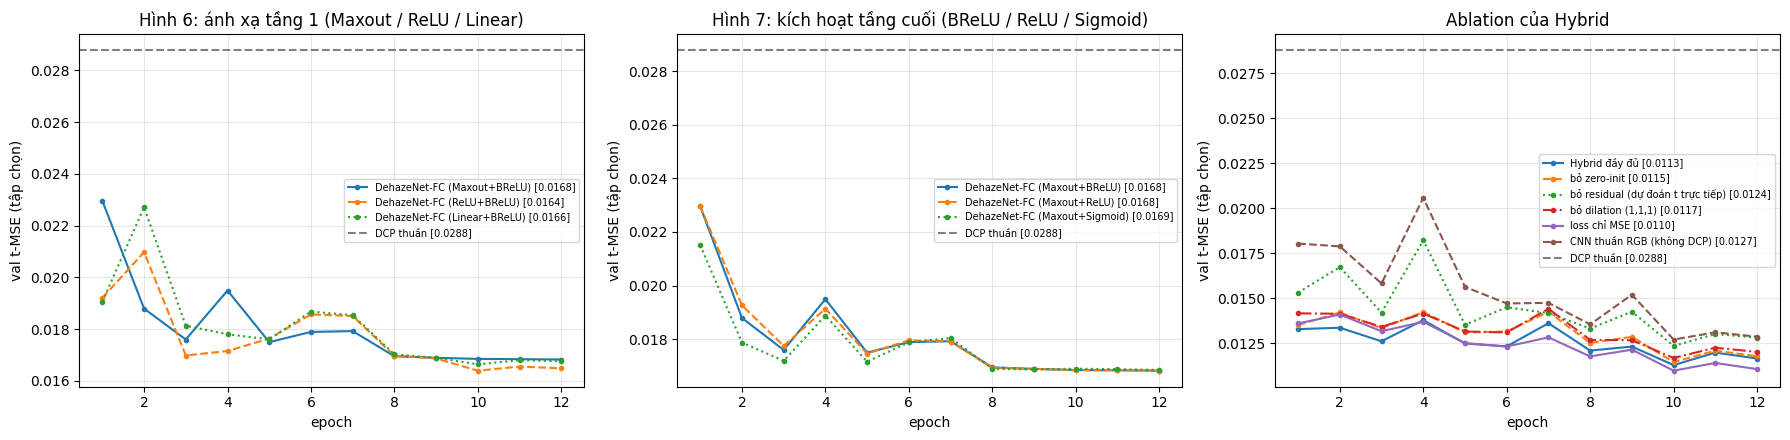

In [ ]:
labels = {
 'hyb_full': 'Hybrid đầy đủ', 'hyb_no_zero': 'bỏ zero-init', 'hyb_no_resid': 'bỏ residual (dự đoán t trực tiếp)',
 'hyb_no_dil': 'bỏ dilation (1,1,1)', 'hyb_mse_only': 'loss chỉ MSE', 'cnn_rgb_only': 'CNN thuần RGB (không DCP)',
 'hyb_ch16': 'độ rộng 16', 'hyb_ch64': 'độ rộng 64',
 'dn_maxout_brelu': 'DehazeNet-FC (Maxout+BReLU)', 'dn_relu_brelu': 'DehazeNet-FC (ReLU+BReLU)', 'dn_linear_brelu': 'DehazeNet-FC (Linear+BReLU)',
 'dn_maxout_relu': 'DehazeNet-FC (Maxout+ReLU)', 'dn_maxout_sigmoid': 'DehazeNet-FC (Maxout+Sigmoid)', 'aodnet': 'AOD-Net',
 'dn_main': 'DehazeNet-FC (ngân sách dài)', 'aod_main': 'AOD-Net (ngân sách dài)'}
kinds = {n: s['kind'] for n, s in VARIANTS.items()}
rows = []
for n in VARIANTS:
    h = hists[n]['hist']
    r = dict(bien_the=n, mo_ta=labels.get(n, n), tham_so=hists[n]['params'], iter=hists[n]['epochs'] * hists[n]['iters'],
             train_MSE_cuoi=h[-1]['train_mse'], val_chon_tot_nhat=min(x['val'] for x in h))
    r['test_t_MSE'] = eval_t_mse(models[n], kinds[n], test_cache) if kinds[n] != 'aod' else np.nan
    rows.append(r)
rows.append(dict(bien_the='main_ckpt', mo_ta='Hybrid chính (30 epoch)', tham_so=n_params(model_main), iter=EPOCHS_MAIN * ITERS_MAIN,
                 train_MSE_cuoi=np.nan, val_chon_tot_nhat=np.nan, test_t_MSE=eval_t_mse(model_main, 'hybrid', test_cache)))
rows.append(dict(bien_the='dcp_thuan', mo_ta='DCP thuần (t thô)', tham_so=0, iter=0, train_MSE_cuoi=np.nan, val_chon_tot_nhat=dcp_sel, test_t_MSE=dcp_test))
t2 = pd.DataFrame(rows)
base = float(t2.loc[t2.bien_the == 'hyb_full', 'test_t_MSE'].iloc[0])
t2['so_voi_hyb_full_%'] = (t2.test_t_MSE / base - 1) * 100
t2.to_csv(os.path.join(BENCH_DIR, 'table2_ablation.csv'), index=False)
display(t2.round(5))
print('Bảng II của bài báo (để đối chiếu xu hướng): DehazeNet 8.240 tham số -> test MSE 1,190e-2; tăng số bộ lọc thì MSE giảm nhưng tham số tăng.')

def curve(ax, names, title, ref=None):
    for i_, n in enumerate(names):
        h = hists[n]['hist']; ax.plot([x['epoch'] for x in h], [x['val'] for x in h], marker='o', ms=3, ls=['-', '--', ':', '-.'][i_ % 4], label=f"{labels.get(n, n)} [{min(x['val'] for x in h):.4f}]")
    if ref is not None: ax.axhline(ref, ls='--', color='gray', label=f'DCP thuần [{ref:.4f}]')
    ax.set_title(title); ax.set_xlabel('epoch'); ax.set_ylabel('val t-MSE (tập chọn)'); ax.grid(alpha=.3); ax.legend(fontsize=7)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
curve(ax[0], ['dn_maxout_brelu', 'dn_relu_brelu', 'dn_linear_brelu'], 'Hình 6: ánh xạ tầng 1 (Maxout / ReLU / Linear)', dcp_sel)
curve(ax[1], ['dn_maxout_brelu', 'dn_maxout_relu', 'dn_maxout_sigmoid'], 'Hình 7: kích hoạt tầng cuối (BReLU / ReLU / Sigmoid)', dcp_sel)
curve(ax[2], ['hyb_full', 'hyb_no_zero', 'hyb_no_resid', 'hyb_no_dil', 'hyb_mse_only', 'cnn_rgb_only'], 'Ablation của Hybrid', dcp_sel)
plt.tight_layout(); plt.savefig(os.path.join(BENCH_DIR, 'fig_convergence.png'), dpi=170); plt.show()

## 9. Hình 8: t dự đoán so với t thật (đường đỏ = trung bình theo bin, đường chéo lý tưởng = nét đứt)

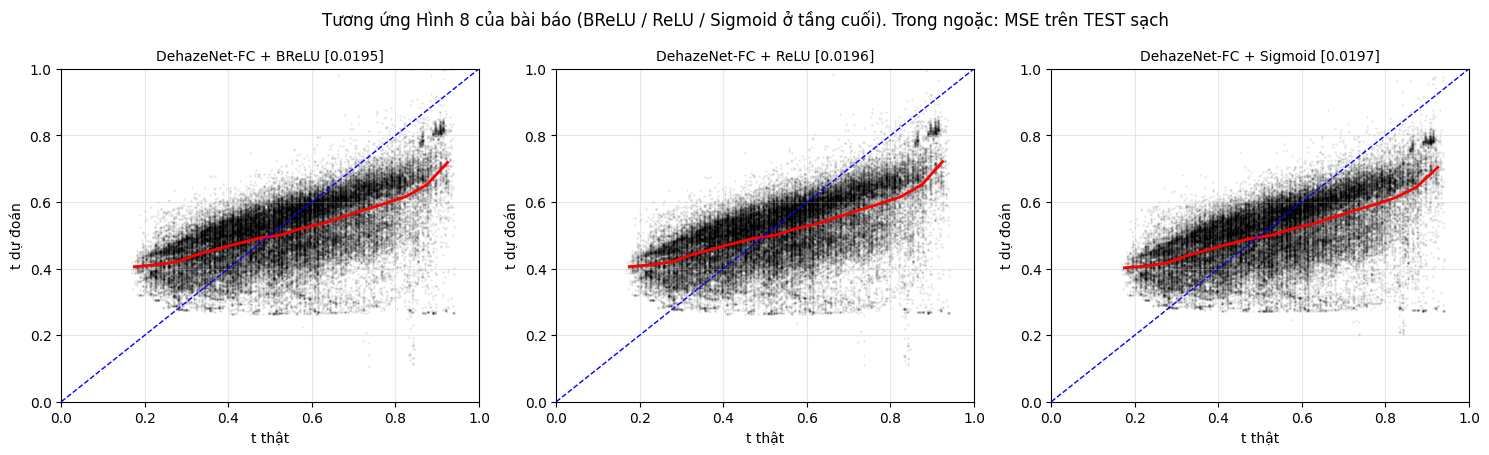

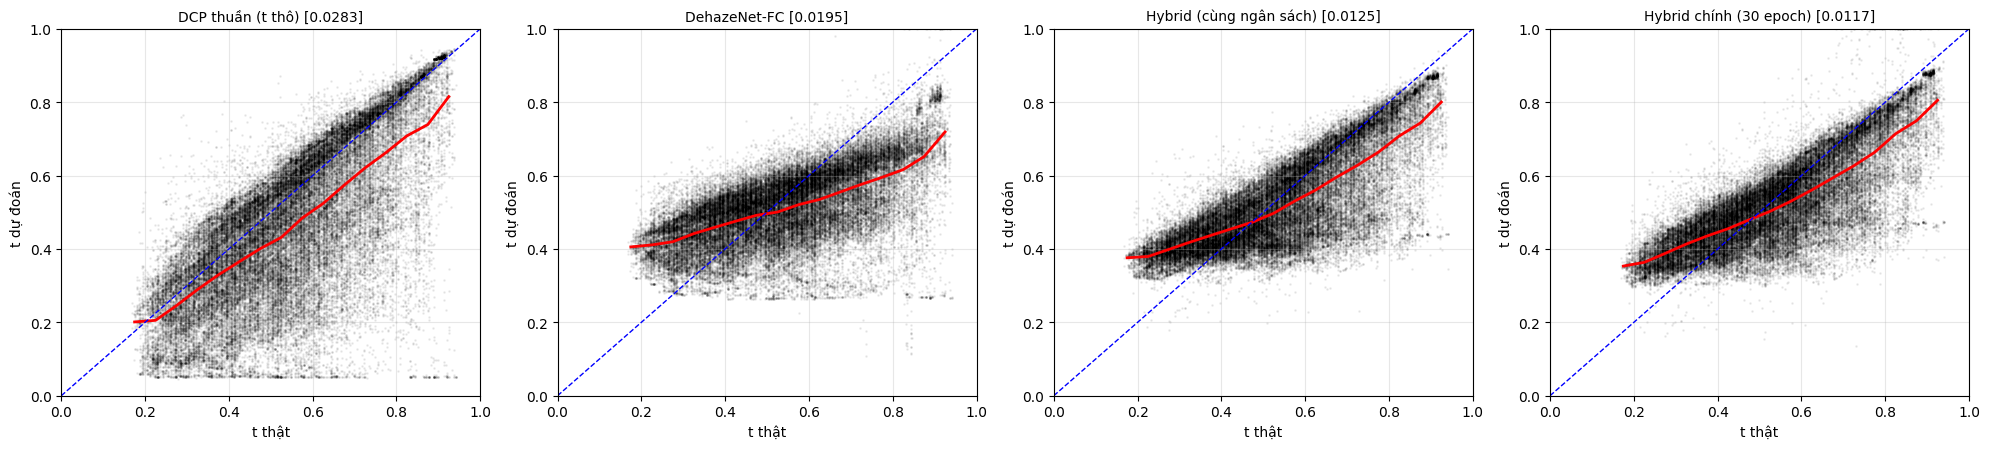

In [ ]:
def collect_pairs(fn, cache, per_img=400, seed=0):
    rng = np.random.default_rng(seed); P, G = [], []
    for c in cache:
        t = fn(c); idx = rng.integers(0, t.size, per_img)
        P.append(t.ravel()[idx]); G.append(c['tg'].ravel()[idx])
    return np.concatenate(P), np.concatenate(G)

def scatter(ax, p, g, title):
    ax.scatter(g, p, s=1, alpha=0.06, color='k', rasterized=True)
    bins = np.linspace(0, 1, 21); ctr = (bins[:-1] + bins[1:]) / 2
    mean = [p[(g >= a) & (g < b)].mean() if ((g >= a) & (g < b)).any() else np.nan for a, b in zip(bins[:-1], bins[1:])]
    ax.plot(ctr, mean, 'r-', lw=2); ax.plot([0, 1], [0, 1], 'b--', lw=1)
    ax.set_title(f'{title} [{np.mean((p - g) ** 2):.4f}]', fontsize=10); ax.set_xlabel('t thật'); ax.set_ylabel('t dự đoán')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=.3)

net_fn = lambda name: (lambda c: predict_t(models[name], c['img'], c['A'], kinds[name]))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, (n, ttl) in zip(ax, (('dn_maxout_brelu', 'BReLU'), ('dn_maxout_relu', 'ReLU'), ('dn_maxout_sigmoid', 'Sigmoid'))):
    scatter(a, *collect_pairs(net_fn(n), test_cache), f'DehazeNet-FC + {ttl}')
plt.suptitle('Tương ứng Hình 8 của bài báo (BReLU / ReLU / Sigmoid ở tầng cuối). Trong ngoặc: MSE trên TEST sạch'); plt.tight_layout()
plt.savefig(os.path.join(BENCH_DIR, 'fig_scatter_t.png'), dpi=170); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
scatter(ax[0], *collect_pairs(lambda c: dcp_t(c['img'], c['A']), test_cache), 'DCP thuần (t thô)')
scatter(ax[1], *collect_pairs(net_fn('dn_maxout_brelu'), test_cache), 'DehazeNet-FC')
scatter(ax[2], *collect_pairs(net_fn('hyb_full'), test_cache), 'Hybrid (cùng ngân sách)')
scatter(ax[3], *collect_pairs(lambda c: predict_t(model_main, c['img'], c['A'], 'hybrid'), test_cache), 'Hybrid chính (30 epoch)')
plt.tight_layout(); plt.savefig(os.path.join(BENCH_DIR, 'fig_scatter_t_methods.png'), dpi=170); plt.show()

## 10. Bảng III: protocol patch của bài báo

Đúng quy trình bài báo: lấy patch 16×16 từ ảnh sạch, với mỗi patch lấy 10 giá trị t ~ U(0,1), **α = 1**, tạo patch sương `I = J·t + 1·(1−t)`, đo MSE giữa t dự đoán và t thật. Mạng của chúng ta là fully-convolutional nên mỗi patch được **phản chiếu (reflect) lên 64×64** rồi lấy trung bình t ở vùng 16×16 giữa (t hằng nên phản chiếu không làm sai nhãn).

Lưu ý khi đối chiếu: bài báo dùng ảnh sạch từ Internet, còn đây dùng ảnh sạch ITS (trong nhà) và mô hình huấn luyện trên sương ITS, nên chỉ so sánh **xu hướng**, không so số tuyệt đối.

In [ ]:
def make_patch_set(items, n_patch, n_t=10, seed=0):
    rng = np.random.default_rng(seed)
    pool = random.Random(seed).sample(items, min(len(items), 200))
    clears = [load_rgb(it['clear']) for it in pool]
    P = np.empty((n_patch, 16, 16, 3), np.float32)
    for i in range(n_patch):
        c = clears[rng.integers(len(clears))]
        y, x = rng.integers(0, c.shape[0] - 15), rng.integers(0, c.shape[1] - 15)
        P[i] = c[y:y + 16, x:x + 16] / 255.
    t = rng.uniform(1e-3, 1.0, size=(n_patch, n_t)).astype(np.float32).reshape(-1)
    J = np.repeat(P[:, None], n_t, 1).reshape(-1, 16, 16, 3)
    return (J * t[:, None, None, None] + (1 - t[:, None, None, None])).astype(np.float32), t

@torch.no_grad()
def patch_pred(kind, model, I, bs=500):
    out = []
    if model is not None: model.eval()
    for s in range(0, len(I), bs):
        x = torch.from_numpy(np.pad(I[s:s + bs], ((0, 0), (24, 24), (24, 24), (0, 0)), mode='reflect')).permute(0, 3, 1, 2).contiguous().to(device)
        At = torch.ones(len(x), 3, 1, 1, device=device)
        if kind == 'dcp': t = dcp_inputs(x, At, 0.95, 15)[1]
        elif kind == 'rgb': t = model(x)
        else:
            dark, tr = dcp_inputs(x, At); t = model(torch.cat([x, dark, tr], 1))
        out.append(t[:, 0, 24:40, 24:40].mean((1, 2)).float().cpu().numpy())
    return np.concatenate(out)

I_p, t_p = make_patch_set(test_items, N_PATCH_IMG)
print('số patch sương tổng hợp:', len(t_p))
t3 = [('DCP thuần (ω=0.95, patch 15, α=1)', 'dcp', None), ('DehazeNet-FC (cùng ngân sách)', 'rgb', models['dn_maxout_brelu']),
      ('Hybrid (cùng ngân sách)', 'hybrid', models['hyb_full']), ('Hybrid chính (30 epoch)', 'hybrid', model_main)]
if 'dn_main' in models: t3.insert(2, ('DehazeNet-FC (ngân sách dài)', 'rgb', models['dn_main']))
rows = [dict(phuong_phap=n, MSE_x1e2=float(np.mean((patch_pred(k, m, I_p) - t_p) ** 2)) * 100, nguon='chạy trong notebook') for n, k, m in t3]
for n, v in (('DCP (bài báo, Bảng III)', 3.18), ('BPNN (bài báo)', 4.37), ('CAP (bài báo)', 3.32), ('RF (bài báo)', 1.26), ('DehazeNet (bài báo)', 1.19)):
    rows.append(dict(phuong_phap=n, MSE_x1e2=v, nguon='trích từ bài báo (dữ liệu khác)'))
t3df = pd.DataFrame(rows); t3df.to_csv(os.path.join(BENCH_DIR, 'table3_patch_protocol.csv'), index=False)
display(t3df.round(3))

số patch sương tổng hợp: 20000


,phuong_phap,MSE_x1e2,nguon
0,"DCP thuần (ω=0.95, patch 15, α=1)",3.154,chạy trong notebook
1,DehazeNet-FC (cùng ngân sách),3.865,chạy trong notebook
2,DehazeNet-FC (ngân sách dài),3.661,chạy trong notebook
3,Hybrid (cùng ngân sách),4.090,chạy trong notebook
4,Hybrid chính (30 epoch),4.080,chạy trong notebook
5,"DCP (bài báo, Bảng III)",3.180,trích từ bài báo (dữ liệu khác)
6,BPNN (bài báo),4.370,trích từ bài báo (dữ liệu khác)
7,CAP (bài báo),3.320,trích từ bài báo (dữ liệu khác)
8,RF (bài báo),1.260,trích từ bài báo (dữ liệu khác)
9,DehazeNet (bài báo),1.190,trích từ bài báo (dữ liệu khác)


## 11. Bảng IV: so sánh trên ảnh đầy đủ (MSE / SSIM / PSNR / WSNR / CIEDE2000 / thời gian)

Mọi phương pháp dùng **A do DCP ước lượng từ ảnh** (không dùng A thật), cùng guided filter và cùng `t_min`. Dòng *Oracle* (t thật + A thật) chỉ là **trần lý thuyết để chẩn đoán**, không phải baseline triển khai.
- Dòng 3 là bộ tham số DCP bạn tối ưu trên O-HAZE (patch 25, ω=0,90, t₀=0,05, guided filter bán kính 40, eps 4e-4), thêm vào để biện luận "cải tiến so với DCP cải tiến".
- Thời gian mỗi ảnh gồm cả bước ước lượng A.

In [ ]:
def mk(kind, **kw):
    d = dict(kind=kind, gf=True, gf_r=GF_R, gf_eps=GF_EPS, tmin=T_MIN, needs_A=True); d.update(kw); return d

METHODS = {
 '1. Hazy (không khử)':                    mk('hazy', needs_A=False),
 '2. DCP+GF (tham số bài báo 15/0.95/0.1)': mk('dcp', win=15, omega=0.95),
 '3. DCP+GF (tối ưu O-HAZE 25/0.90/0.05)':  mk('dcp', win=25, omega=0.90, tmin=0.05, gf_r=40, gf_eps=4e-4),
 '4. AOD-Net (cùng ngân sách)':            mk('aod', model=models['aodnet'], needs_A=False),
 '5. DehazeNet-FC (cùng ngân sách)':       mk('net', model=models['dn_maxout_brelu'], input='rgb'),
 '6. Hybrid (cùng ngân sách)':             mk('net', model=models['hyb_full'], input='hybrid'),
}
if 'aod_main' in models:
    METHODS['7. AOD-Net (ngân sách dài)'] = mk('aod', model=models['aod_main'], needs_A=False)
    METHODS['8. DehazeNet-FC (ngân sách dài)'] = mk('net', model=models['dn_main'], input='rgb')
METHODS['9. Hybrid chính (30 epoch) + GF'] = mk('net', model=model_main, input='hybrid')
METHODS['10. Hybrid chính, không GF'] = mk('net', model=model_main, input='hybrid', gf=False)
ORACLE = '11. Oracle (t thật + A thật, chỉ ITS)'
K_NAME = {k.split('.')[0]: k for k in list(METHODS) + [ORACLE]}

def run_method(m, img_u8, img, A, gray, tg=None, A_gt=None, dev=None):
    k = m['kind']; sync(); t0 = time.perf_counter()
    if k == 'hazy': J, t = img, None
    elif k == 'oracle': J, t = recover(img, tg, A_gt, m['tmin']), tg
    elif k == 'aod': J, t = predict_aod(m['model'], img_u8, dev=dev), None
    else:
        t = dcp_t(img_u8, A, m['win'], m['omega'], dev=dev) if k == 'dcp' else predict_t(m['model'], img_u8, A, m['input'], dev=dev)
        if m['gf']: t = np.clip(guided_filter(gray, t, m['gf_r'], m['gf_eps']), 0, 1)
        J = recover(img, t, A, m['tmin'])
    sync(); return J, t, (time.perf_counter() - t0) * 1000

def evaluate_set(name, items, methods, n=None, max_side=None, with_t=False, oracle=False, seed=1, full=True):
    sub = items if n is None else random.Random(seed).sample(items, min(n, len(items)))
    rows = []
    for it in tqdm(sub, desc=name):
        img_u8 = load_rgb_max(it['hazy'], max_side); img = img_u8.astype(np.float32) / 255.
        gt = load_rgb(it['clear'], img.shape[:2]).astype(np.float32) / 255.
        tg = load_trans(it['trans'], img.shape[:2]) if (with_t and it.get('trans')) else None
        sync(); t0 = time.perf_counter(); A = estimate_A_np(img_u8); tA = (time.perf_counter() - t0) * 1000
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); bm = bright_mask(gt)
        scene = it.get('id') if it.get('trans') else os.path.basename(it['hazy']).split('_')[0]
        todo = dict(methods)
        if oracle and tg is not None: todo[ORACLE] = mk('oracle', needs_A=False)
        for mname, m in todo.items():
            A_gt = np.array([it['A']] * 3, np.float32) if it.get('A') else A
            J, t, ms = run_method(m, img_u8, img, A, gray, tg=tg, A_gt=A_gt)
            ms += tA if m['needs_A'] else 0.0
            r = dict(dataset=name, method=mname, scene=scene, file=os.path.basename(it['hazy']), ms=ms, **img_metrics(J, gt, full=full))
            err = ((J - gt) ** 2).mean(2)
            r['bright_frac'] = float(bm.mean()); r['MSE_bright'] = float(err[bm].mean()) if bm.sum() >= 500 else np.nan
            r['MSE_rest'] = float(err[~bm].mean()) if (~bm).sum() > 0 else np.nan
            if tg is not None and t is not None:
                r['T_MSE'] = float(((t - tg) ** 2).mean()); r['T_MAE'] = float(np.abs(t - tg).mean())
            rows.append(r)
    return pd.DataFrame(rows)

def summarize(df):
    cols = [c for c in ['MSE', 'SSIM', 'PSNR', 'WSNR', 'CIEDE2000', 'T_MSE', 'T_MAE', 'ms'] if c in df]
    return df.groupby('method', sort=False)[cols].mean()

results = {}
results['ITS-test'] = evaluate_set('ITS-test', test_items, METHODS, n=N_TEST_IMGS, with_t=True, oracle=True)
for name, (hd, gd) in SOTS_DIRS.items():
    hz, gt_ = index_dir(hd), index_dir(gd)
    items = [dict(hazy=p, clear=gt_[s.split('_')[0]], trans=None, A=None, id=s.split('_')[0]) for s, p in sorted(hz.items()) if s.split('_')[0] in gt_]
    print(f'SOTS {name}: {len(items)} cặp')
    results['SOTS-' + name] = evaluate_set('SOTS-' + name, items, METHODS, n=N_SOTS)
if OHAZE_HAZY and OHAZE_GT and os.path.isdir(OHAZE_HAZY):
    hz, gt_ = index_dir(OHAZE_HAZY), index_dir(OHAZE_GT); items = []
    for s, p in sorted(hz.items()):
        b = s.replace('_hazy', '').replace('_Hazy', '')
        g = gt_.get(b + '_GT') or gt_.get(b) or gt_.get(s)
        if g: items.append(dict(hazy=p, clear=g, trans=None, A=None, id=b))
    print('O-HAZE:', len(items), 'cặp (thu nhỏ cạnh dài còn 800 px, như thí nghiệm DCP trước)')
    results['O-HAZE'] = evaluate_set('O-HAZE', items, METHODS, max_side=800)

t4 = pd.concat([summarize(d).assign(dataset=k).reset_index() for k, d in results.items()])
t4 = t4[['dataset', 'method'] + [c for c in t4.columns if c not in ('dataset', 'method')]]
t4.to_csv(os.path.join(BENCH_DIR, 'table4_images.csv'), index=False)
pd.concat(results.values()).to_csv(os.path.join(BENCH_DIR, 'per_image_all.csv'), index=False)
for k, d in results.items():
    print(f'\n=== {k}  ({d.file.nunique()} ảnh, {d.scene.nunique()} cảnh) ==='); display(summarize(d).round(4))

ITS-test:   0%|          | 0/300 [00:00<?, ?it/s]

SOTS outdoor: 500 cặp


SOTS-outdoor:   0%|          | 0/500 [00:00<?, ?it/s]

SOTS indoor: 500 cặp


SOTS-indoor:   0%|          | 0/500 [00:00<?, ?it/s]

...

,MSE,SSIM,PSNR,WSNR,CIEDE2000,T_MSE,T_MAE,ms
method,,,,,,,,
1. Hazy (không khử),0.0628,0.7025,13.1478,6.7409,18.7631,NaN,NaN,0.0131
2. DCP+GF (tham số bài báo 15/0.95/0.1),0.0279,0.8166,16.6377,9.3767,11.5047,0.0274,0.1180,18.4927
3. DCP+GF (tối ưu O-HAZE 25/0.90/0.05),0.0169,0.8478,18.9447,10.4364,8.8983,0.0171,0.0966,20.7515
4. AOD-Net (cùng ngân sách),0.0184,0.8091,18.1286,6.0086,9.4953,NaN,NaN,10.3829
5. DehazeNet-FC (cùng ngân sách),0.0223,0.7557,18.2237,10.9954,10.5101,0.0179,0.1077,55.2739
6. Hybrid (cùng ngân sách),0.0172,0.8480,19.3661,11.9920,8.8571,0.0132,0.0863,34.3715
7. AOD-Net (ngân sách dài),0.0181,0.8118,18.2139,6.2195,9.4329,NaN,NaN,10.3871
8. DehazeNet-FC (ngân sách dài),0.0223,0.7523,18.2996,11.1216,10.4928,0.0176,0.1056,55.2522
9. Hybrid chính (30 epoch) + GF,0.0170,0.8360,19.5563,12.2737,8.8592,0.0121,0.0831,34.3703



=== SOTS-outdoor  (500 ảnh, 492 cảnh) ===


,MSE,SSIM,PSNR,WSNR,CIEDE2000,ms
method,,,,,,
1. Hazy (không khử),0.0324,0.8139,15.9194,9.9598,12.9834,0.0141
2. DCP+GF (tham số bài báo 15/0.95/0.1),0.0272,0.8552,16.8566,11.9892,10.6594,17.9171
3. DCP+GF (tối ưu O-HAZE 25/0.90/0.05),0.0131,0.9113,20.0926,13.8952,7.5674,20.0191
4. AOD-Net (cùng ngân sách),0.0155,0.8637,18.8924,8.8793,8.8167,10.3175
5. DehazeNet-FC (cùng ngân sách),0.0258,0.6844,16.8840,12.1927,11.5450,51.7358
6. Hybrid (cùng ngân sách),0.0124,0.8752,20.1311,15.7443,7.8569,32.7371
7. AOD-Net (ngân sách dài),0.0157,0.8540,18.8638,8.9733,8.9638,9.6981
8. DehazeNet-FC (ngân sách dài),0.0299,0.6450,16.1053,11.4633,12.3842,52.2254
9. Hybrid chính (30 epoch) + GF,0.0130,0.8476,20.1504,15.6550,8.0221,32.6196



=== SOTS-indoor  (500 ảnh, 50 cảnh) ===


,MSE,SSIM,PSNR,WSNR,CIEDE2000,ms
method,,,,,,
1. Hazy (không khử),0.0747,0.6934,11.9748,7.5034,20.3176,0.0151
2. DCP+GF (tham số bài báo 15/0.95/0.1),0.0141,0.8609,19.4090,10.5025,7.5653,19.2163
3. DCP+GF (tối ưu O-HAZE 25/0.90/0.05),0.0090,0.8693,21.2091,12.0327,6.1425,21.4804
4. AOD-Net (cùng ngân sách),0.0170,0.8289,18.9198,7.8616,8.3999,10.5168
5. DehazeNet-FC (cùng ngân sách),0.0128,0.7938,19.8835,11.7267,7.8883,55.7746
6. Hybrid (cùng ngân sách),0.0092,0.8850,21.7418,13.4408,6.0371,35.3402
7. AOD-Net (ngân sách dài),0.0171,0.8327,18.9416,8.0744,8.4663,10.4931
8. DehazeNet-FC (ngân sách dài),0.0121,0.7979,20.2058,11.9013,7.6625,55.9386
9. Hybrid chính (30 epoch) + GF,0.0086,0.8782,21.9218,13.6040,5.9441,35.1939


### 11b. Khoảng tin cậy 95% **theo cảnh** (bootstrap trên cảnh, so sánh ghép cặp) và phân tích vùng sáng/trời

In [ ]:
def paired_ci(df, a, b, metric, n_boot=3000, seed=0):
    A_ = df[df.method == a].set_index('file'); B_ = df[df.method == b].set_index('file')
    d = (A_[metric] - B_.loc[A_.index, metric]).groupby(A_['scene']).mean().dropna().values
    rng = np.random.default_rng(seed)
    boots = np.array([rng.choice(d, len(d)).mean() for _ in range(n_boot)])
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5), len(d)

pairs = [('6', '2', 'Hybrid(cùng NS) − DCP bài báo'), ('6', '5', 'Hybrid(cùng NS) − DehazeNet-FC'), ('6', '4', 'Hybrid(cùng NS) − AOD-Net'),
         ('9', '2', 'Hybrid chính − DCP bài báo'), ('9', '3', 'Hybrid chính − DCP tối ưu O-HAZE'), ('9', '5', 'Hybrid chính − DehazeNet-FC')]
rows = []
for ds, d in results.items():
    for a, b, lab in pairs:
        for met in ('PSNR', 'SSIM'):
            m, lo, hi, n = paired_ci(d, K_NAME[a], K_NAME[b], met)
            rows.append(dict(tap=ds, so_sanh=lab, chi_so=met, khac_biet_TB=m, CI95_thap=lo, CI95_cao=hi, so_canh=n, khac_0=('CÓ' if lo > 0 or hi < 0 else 'không')))
ci = pd.DataFrame(rows); ci.to_csv(os.path.join(BENCH_DIR, 'ci_by_scene.csv'), index=False)
display(ci.round(4))
print('"khac_0 = CÓ": khoảng tin cậy 95% theo cảnh không chứa 0, tức khác biệt ổn định qua các cảnh (không chỉ do một vài ảnh).')

# vùng sáng mạnh / gần như không màu (xấp xỉ trời, đèn, vật trắng)
rows = []
for ds, d in results.items():
    for mname, g in d.groupby('method', sort=False):
        rows.append(dict(tap=ds, method=mname, ti_le_vung_sang=g.bright_frac.mean(), MSE_vung_sang=g.MSE_bright.mean(), MSE_vung_con_lai=g.MSE_rest.mean()))
br = pd.DataFrame(rows); br.to_csv(os.path.join(BENCH_DIR, 'bright_region_analysis.csv'), index=False)
display(br.round(5))
print('Vùng sáng = pixel của ảnh sạch có độ chói > 0,85 và độ bão hòa < 0,15 (heuristic, KHÔNG phải phân vùng trời có nhãn). '
      'Nếu MSE vùng sáng lớn hơn hẳn vùng còn lại ở DCP và giảm ở Hybrid thì CNN giúp ở đúng điểm yếu kinh điển của DCP.')

,tap,so_sanh,chi_so,khac_biet_TB,CI95_thap,CI95_cao,so_canh,khac_0
0,ITS-test,Hybrid(cùng NS) − DCP bài báo,PSNR,2.7929,2.0171,3.5726,49,CÓ
1,ITS-test,Hybrid(cùng NS) − DCP bài báo,SSIM,0.0322,0.0174,0.0464,49,CÓ
2,ITS-test,Hybrid(cùng NS) − DehazeNet-FC,PSNR,1.1833,0.8407,1.5846,49,CÓ
3,ITS-test,Hybrid(cùng NS) − DehazeNet-FC,SSIM,0.0925,0.0708,0.1166,49,CÓ
4,ITS-test,Hybrid(cùng NS) − AOD-Net,PSNR,1.3813,0.7162,2.0416,49,CÓ
5,ITS-test,Hybrid(cùng NS) − AOD-Net,SSIM,0.0423,0.0273,0.0557,49,CÓ
6,ITS-test,Hybrid chính − DCP bài báo,PSNR,2.9718,2.0928,3.8494,49,CÓ
7,ITS-test,Hybrid chính − DCP bài báo,SSIM,0.0199,0.0012,0.0370,49,CÓ
8,ITS-test,Hybrid chính − DCP tối ưu O-HAZE,PSNR,0.6726,0.0362,1.3119,49,CÓ
9,ITS-test,Hybrid chính − DCP tối ưu O-HAZE,SSIM,-0.0115,-0.0311,0.0054,49,không


"khac_0 = CÓ": khoảng tin cậy 95% theo cảnh không chứa 0, tức khác biệt ổn định qua các cảnh (không chỉ do một vài ảnh).


,tap,method,ti_le_vung_sang,MSE_vung_sang,MSE_vung_con_lai
0,ITS-test,1. Hazy (không khử),0.06387,0.00584,0.06586
1,ITS-test,2. DCP+GF (tham số bài báo 15/0.95/0.1),0.06387,0.02659,0.02751
2,ITS-test,3. DCP+GF (tối ưu O-HAZE 25/0.90/0.05),0.06387,0.01464,0.01661
3,ITS-test,4. AOD-Net (cùng ngân sách),0.06387,0.02377,0.01779
4,ITS-test,5. DehazeNet-FC (cùng ngân sách),0.06387,0.01075,0.02248
5,ITS-test,6. Hybrid (cùng ngân sách),0.06387,0.00973,0.01719
6,ITS-test,7. AOD-Net (ngân sách dài),0.06387,0.02257,0.01758
7,ITS-test,8. DehazeNet-FC (ngân sách dài),0.06387,0.01127,0.02246
8,ITS-test,9. Hybrid chính (30 epoch) + GF,0.06387,0.00995,0.01702
9,ITS-test,"10. Hybrid chính, không GF",0.06387,0.01016,0.01781


Vùng sáng = pixel của ảnh sạch có độ chói > 0,85 và độ bão hòa < 0,15 (heuristic, KHÔNG phải phân vùng trời có nhãn). Nếu MSE vùng sáng lớn hơn hẳn vùng còn lại ở DCP và giảm ở Hybrid thì CNN giúp ở đúng điểm yếu kinh điển của DCP.


## 12. Bảng V: độ bền (CRE / ARE / SRE / NRE) trên ảnh **tổng hợp lại từ cảnh TEST**

Từ ảnh sạch `J` và bản đồ truyền dẫn thật `t` của ITS, tạo lại sương với tham số khác (cách làm như bài báo trên Middlebury):
- **CRE**: đổi độ dày sương, `t → t^γ` (tương đương nhân hệ số tán xạ β lên γ lần), γ ∈ {0,75; 1; 1,25; 1,5}, A = 1.
- **ARE**: đổi màu ánh sáng khí quyển A ∈ {[1,1,1], [0,9,1,1], [1,0,9,1], [1,1,0,9]}.
- **SRE**: đổi tỉ lệ ảnh s ∈ {0,4; 0,6; 0,8; 1,0}.
- **NRE**: thêm nhiễu Gauss σ ∈ {10, 15, 20, 25, 30} (thang 0–255).

Mỗi cảnh test lấy **một** biến thể. Đây là sương tổng hợp từ ITS nên chỉ đánh giá độ bền **trong miền** (không thay thế phép thử trên sương thật).

số cảnh dùng cho Bảng V: 49


độ bền:   0%|          | 0/17 [00:00<?, ?it/s]

MSE (thang 0–1, càng thấp càng tốt), giống định dạng Bảng V của bài báo:


method              1. Hazy (không khử)  \
nhom                                      
ARE  A=(1, 1, 1)                0.09569   
     A=(0.9, 1, 1)              0.08833   
     A=(1, 0.9, 1)              0.08740   
     A=(1, 1, 0.9)              0.08724   
     TRUNG BÌNH                 0.08967   
CRE  γ=0.75                     0.06438   
     γ=1.0                      0.09569   
     γ=1.25                     0.12638   
     γ=1.5                      0.15537   
     TRUNG BÌNH                 0.11045   
NRE  σ=10                       0.09715   
     σ=15                       0.09893   
     σ=20                       0.10133   
     σ=25                       0.10425   
     σ=30                       0.10767   
     TRUNG BÌNH                 0.10187   
SRE  s=0.4                      0.09538   
     s=0.6                      0.09550   
     s=0.8                      0.09555   
     s=1.0                      0.09569   
     TRUNG BÌNH                 0.09553   

method              2. DCP+GF (tham số bài báo 15/0.95/0.1)  \
nhom                                                          
ARE  A=(1, 1, 1)                                    0.02038   
     A=(0.9, 1, 1)                                  0.02239   
     A=(1, 0.9, 1)                                  0.02133   
     A=(1, 1, 0.9)                                  0.02172   
     TRUNG BÌNH                                     0.02146   
CRE  γ=0.75                                         0.02152   
     γ=1.0                                          0.02038   
     γ=1.25                                         0.02039   
     γ=1.5                                          0.02109   
     TRUNG BÌNH                                     0.02084   
NRE  σ=10                                           0.02631   
     σ=15                                           0.03932   
     σ=20                                           0.05480   
     σ=25                                           0.07011   
     σ=30                                           0.08414   
     TRUNG BÌNH                                     0.05493   
SRE  s=0.4                                          0.01526   
     s=0.6                                          0.01700   
     s=0.8                                          0.01895   
     s=1.0                                          0.02038   
     TRUNG BÌNH                                     0.01790   

method              4. AOD-Net (cùng ngân sách)  \
nhom                                              
ARE  A=(1, 1, 1)                        0.02512   
     A=(0.9, 1, 1)                      0.01995   
     A=(1, 0.9, 1)                      0.02173   
     A=(1, 1, 0.9)                      0.02482   
     TRUNG BÌNH                         0.02291   
CRE  γ=0.75                             0.01357   
     γ=1.0                              0.02512   
     γ=1.25                             0.04338   
     γ=1.5                              0.06567   
     TRUNG BÌNH                         0.03694   
NRE  σ=10                               0.02906   
     σ=15                               0.03374   
     σ=20                               0.03991   
     σ=25                               0.04729   
     σ=30                               0.05561   
     TRUNG BÌNH                         0.04112   
SRE  s=0.4                              0.02698   
     s=0.6                              0.02593   
     s=0.8                              0.02541   
     s=1.0                              0.02512   
     TRUNG BÌNH                         0.02586   

method              5. DehazeNet-FC (cùng ngân sách)  \
nhom                                                   
ARE  A=(1, 1, 1)                             0.02076   
     A=(0.9, 1, 1)                           0.02014   
     A=(1, 0.9, 1)                           0.02140   
     A=(1, 1, 0.9)                           0.02094   
     TRUNG BÌNH                              0.020

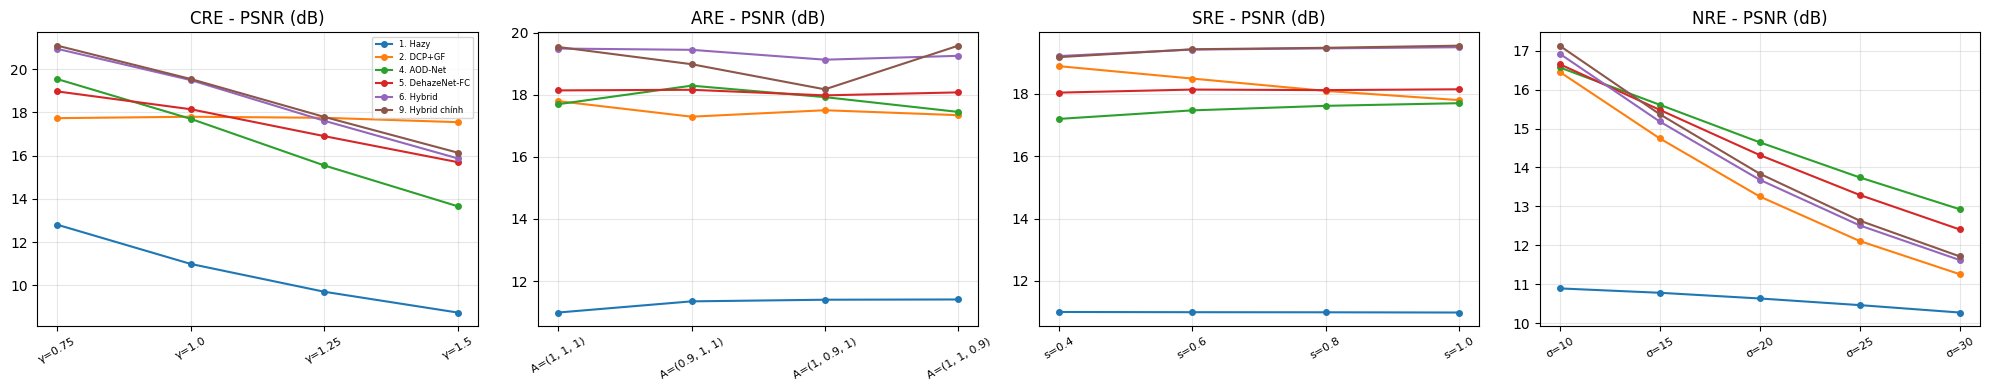

In [ ]:
RB_METHODS = {k: v for k, v in METHODS.items() if k.split('.')[0] in ('1', '2', '4', '5', '6', '9')}
base_scenes = {}
for it in test_items: base_scenes.setdefault(it['id'], it)
base = []
for it in list(base_scenes.values())[:N_ROBUST]:
    J = load_rgb(it['clear']).astype(np.float32) / 255.
    base.append((J, load_trans(it['trans'], J.shape[:2])))
print('số cảnh dùng cho Bảng V:', len(base))

def synth(J, t, gamma=1.0, A=(1, 1, 1), scale=1.0, sigma=0.0, rng=None):
    tg = np.clip(t, 1e-3, 1) ** gamma
    I = J * tg[..., None] + np.array(A, np.float32) * (1 - tg[..., None])
    if scale != 1.0:
        sz = (max(int(I.shape[1] * scale), 32), max(int(I.shape[0] * scale), 32))
        I, J = cv2.resize(I, sz, interpolation=cv2.INTER_AREA), cv2.resize(J, sz, interpolation=cv2.INTER_AREA)
    I = I * 255.
    if sigma > 0: I = I + rng.normal(0, sigma, I.shape)
    return np.clip(np.round(I), 0, 255).astype(np.uint8), J

CFGS = ([('CRE', f'γ={g}', dict(gamma=g)) for g in (0.75, 1.0, 1.25, 1.5)] +
        [('ARE', 'A=' + str(a), dict(A=a)) for a in ((1, 1, 1), (0.9, 1, 1), (1, 0.9, 1), (1, 1, 0.9))] +
        [('SRE', f's={s}', dict(scale=s)) for s in (0.4, 0.6, 0.8, 1.0)] +
        [('NRE', f'σ={s}', dict(sigma=s)) for s in (10, 15, 20, 25, 30)])
rng = np.random.default_rng(0); rows = []
for grp, lab, kw in tqdm(CFGS, desc='độ bền'):
    for J0, t0 in base:
        I_u8, J = synth(J0, t0, rng=rng, **kw); img = I_u8.astype(np.float32) / 255.
        A = estimate_A_np(I_u8); gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        for mname, m in RB_METHODS.items():
            out, _, _ = run_method(m, I_u8, img, A, gray)
            mse = float(np.mean((out - J) ** 2)); rows.append(dict(nhom=grp, thiet_lap=lab, method=mname, MSE=mse, PSNR=min(10 * np.log10(1 / max(mse, 1e-10)), 100)))
rb_ps = pd.DataFrame(rows); rb_ps.to_csv(os.path.join(BENCH_DIR, 'table5_robustness_per_scene.csv'), index=False)
rb = rb_ps.groupby(['nhom', 'thiet_lap', 'method'], sort=False)[['MSE', 'PSNR']].mean().reset_index()      # trung bình theo cảnh
rb.to_csv(os.path.join(BENCH_DIR, 'table5_robustness.csv'), index=False)
tab = rb.pivot_table(index=['nhom', 'thiet_lap'], columns='method', values='MSE', sort=False)
avg = rb.groupby(['nhom', 'method'], sort=False).MSE.mean().unstack('method'); avg.index = pd.MultiIndex.from_product([avg.index, ['TRUNG BÌNH']])
tab = pd.concat([tab, avg]).sort_index(level=0, sort_remaining=False)
print('MSE (thang 0–1, càng thấp càng tốt), giống định dạng Bảng V của bài báo:'); display(tab.round(5))
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, grp in zip(ax, ('CRE', 'ARE', 'SRE', 'NRE')):
    d = rb[rb.nhom == grp]
    for mname, g in d.groupby('method', sort=False):
        a.plot(range(len(g)), g.PSNR.values, 'o-', label=mname.split('(')[0].strip(), ms=4)
    a.set_xticks(range(len(d.thiet_lap.unique()))); a.set_xticklabels(d.thiet_lap.unique(), rotation=30, fontsize=8)
    a.set_title(grp + ' - PSNR (dB)'); a.grid(alpha=.3)
ax[0].legend(fontsize=6); plt.tight_layout(); plt.savefig(os.path.join(BENCH_DIR, 'fig_robustness.png'), dpi=170); plt.show()

## 13. Thời gian từng khâu (640×480) và quy đổi FPS: chỉ nói "thời gian thực" nếu số đo này đủ

`A`, guided filter và khôi phục chạy trên CPU (OpenCV/numpy); phần mạng chạy GPU hoặc CPU. Trung vị của 15 lần đo sau 3 lần khởi động.

In [3]:
def med(f, n=15, warm=3):
    for _ in range(warm): f()
    ts = []
    for _ in range(n):
        sync(); t0 = time.perf_counter(); f(); sync(); ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

it0 = test_items[0]
img_u8 = cv2.resize(load_rgb(it0['hazy']), (640, 480), interpolation=cv2.INTER_AREA); img = img_u8.astype(np.float32) / 255.
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY); A0 = estimate_A_np(img_u8); cpu = torch.device('cpu')
tA = med(lambda: estimate_A_np(img_u8)); t_ = np.random.rand(480, 640).astype(np.float32)
tG = med(lambda: guided_filter(gray, t_, GF_R, GF_EPS)); tR = med(lambda: recover(img, t_, A0))
cpu_copy = lambda m: copy.deepcopy(m).cpu().eval()
cfg = [('DCP + GF', 'dcp', None, None), ('AOD-Net', 'aod', models['aodnet'], None), ('DehazeNet-FC + GF', 'net', models['dn_maxout_brelu'], 'rgb'),
       ('Hybrid + GF', 'net', model_main, 'hybrid')]
rows = []
for nm, k, m, inp in cfg:
    for dn_, dev_ in (('GPU' if device.type == 'cuda' else 'CPU', device), ('CPU', cpu)):
        if dn_ == 'CPU' and device.type != 'cuda' and rows and rows[-1]['phuong_phap'] == nm: continue
        mm = (cpu_copy(m) if (m is not None and dev_.type == 'cpu') else m)
        if k == 'dcp': fn = lambda: dcp_t(img_u8, A0, dev=dev_)
        elif k == 'aod': fn = lambda: predict_aod(mm, img_u8, dev=dev_)
        else: fn = lambda: predict_t(mm, img_u8, A0, inp, dev=dev_)
        tN = med(fn); need_A, need_gf = k != 'aod', k != 'aod'
        tot = tN + (tA if need_A else 0) + ((tG) if need_gf else 0) + (tR if need_gf else 0)
        rows.append(dict(phuong_phap=nm, mang_chay_tren=dn_, tham_so=(n_params(m) if m is not None else 0), A_ms=tA if need_A else 0,
                         mang_ms=tN, GF_ms=tG if need_gf else 0, khoi_phuc_ms=tR if need_gf else 0, tong_ms=tot, FPS=1000 / tot))
tm = pd.DataFrame(rows); tm.to_csv(os.path.join(BENCH_DIR, 'timing_640x480.csv'), index=False); display(tm.round(2))
print('Máy đo:', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU', '| số luồng CPU:', os.cpu_count(),
      '\nBài báo DehazeNet: ~1,5 giây cho ảnh 640×480 trên CPU i7 3770 (MATLAB, bản 2016). Số đo của bạn là số đo trên đúng máy này, hãy ghi rõ cấu hình khi báo cáo.')

NameError: name 'test_items' is not defined

## 14. Hình trước-sau: **cùng vùng cắt phóng to**, có chú thích PSNR/SSIM

Vùng cắt cố định ở giữa ảnh (không chọn theo kết quả) để không bị coi là chọn ảnh có lợi.

In [ ]:
Q_KEYS = ['2', '5', '4', '6', '9']
def fig_qualitative(items, tag, k=3, seed=3, frac=0.35, max_side=None, with_gt=True):
    sel = random.Random(seed).sample(items, min(k, len(items)))
    ncol = 1 + len(Q_KEYS) + (1 if with_gt else 0)
    fig, ax = plt.subplots(2 * len(sel), ncol, figsize=(3.1 * ncol, 2.7 * 2 * len(sel)), squeeze=False)
    for r, it in enumerate(sel):
        img_u8 = load_rgb_max(it['hazy'], max_side); img = img_u8.astype(np.float32) / 255.
        gt = load_rgb(it['clear'], img.shape[:2]).astype(np.float32) / 255. if with_gt else None
        A = estimate_A_np(img_u8); gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        H, W = img.shape[:2]; h, w = int(H * frac), int(W * frac); y0, x0 = (H - h) // 2, (W - w) // 2
        panels = [('Hazy', img)] + [(K_NAME[q].split('(')[0].split('.', 1)[1].strip() + ' [' + q + ']', run_method(METHODS[K_NAME[q]], img_u8, img, A, gray)[0]) for q in Q_KEYS]
        if with_gt: panels.append(('Ảnh sạch (GT)', gt))
        for c, (ttl, im) in enumerate(panels):
            cap = ttl
            if with_gt and ttl not in ('Hazy', 'Ảnh sạch (GT)'):
                m_ = img_metrics(im, gt, full=False); cap += f"\n{m_['PSNR']:.2f} dB / {m_['SSIM']:.3f}"
            ax[2 * r, c].imshow(im); ax[2 * r, c].add_patch(plt.Rectangle((x0, y0), w, h, fill=False, ec='red', lw=1.5))
            ax[2 * r, c].set_title(cap, fontsize=8); ax[2 * r, c].axis('off')
            ax[2 * r + 1, c].imshow(im[y0:y0 + h, x0:x0 + w]); ax[2 * r + 1, c].axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(BENCH_DIR, f'fig_qualitative_{tag}.png'), dpi=150); plt.show()

fig_qualitative(test_items, 'ITS-test')
for name, (hd, gd) in SOTS_DIRS.items():
    hz, gt_ = index_dir(hd), index_dir(gd)
    fig_qualitative([dict(hazy=p, clear=gt_[s.split('_')[0]]) for s, p in sorted(hz.items()) if s.split('_')[0] in gt_], 'SOTS-' + name)
if OHAZE_HAZY and OHAZE_GT and os.path.isdir(OHAZE_HAZY):
    fig_qualitative(items, 'O-HAZE', max_side=800)
if REAL_DIR and os.path.isdir(REAL_DIR):
    real = [dict(hazy=os.path.join(REAL_DIR, f)) for f in sorted(os.listdir(REAL_DIR)) if f.lower().endswith(IMG_EXT)]
    fig_qualitative(real, 'real_no_GT', max_side=800, with_gt=False)

## 15. Tổng hợp và đối chiếu với bài báo

In [ ]:
paper = pd.DataFrame([
    ('Số tham số DehazeNet', 8240, 'Bảng II / Mục IV-A'),
    ('MSE test patch, BReLU (×1e-2)', 1.19, 'Hình 8: [0,0119]'), ('MSE test patch, ReLU (×1e-2)', 1.28, 'Hình 8: [0,0128]'), ('MSE test patch, Sigmoid (×1e-2)', 1.46, 'Hình 8: [0,0146]'),
    ('Hội tụ tầng 1: Maxout / ReLU / Linear', '0,0109 / 0,0140 / 0,0140', 'Hình 6 (chú giải)'),
    ('Bảng IV, DehazeNet (Middlebury, β=1, α=1): MSE / SSIM / PSNR / WSNR', '0,0062 / 0,9993 / 70,98 / 18,10', 'Bảng IV'),
    ('Bảng IV, DCP: MSE / SSIM / PSNR / WSNR', '0,0172 / 0,9981 / 66,74 / 13,85', 'Bảng IV'),
    ('Thời gian ảnh 640×480', '≈1,5 s (CPU i7-3770, MATLAB)', 'Mục IV')], columns=['hang_muc', 'gia_tri_bai_bao', 'nguon'])
paper.to_csv(os.path.join(BENCH_DIR, 'paper_reference_numbers.csv'), index=False); display(paper)
print('LƯU Ý khi đối chiếu: bài báo đo trên ảnh Middlebury tổng hợp với PSNR/WSNR theo cách tính riêng (PSNR 70 dB không khớp công thức chuẩn với MSE 0,0062), '
      'nên không đặt số PSNR của bạn cạnh số PSNR của họ. Chỉ so XU HƯỚNG: Maxout > ReLU/Linear, BReLU > ReLU > Sigmoid, DehazeNet-FC > DCP, và thứ tự các phương pháp trên cùng dữ liệu của bạn.')

# thứ tự kỳ vọng từ bài báo, kiểm tra trên dữ liệu của bạn (kết quả có thể ĐÚNG hoặc SAI, cả hai đều là thông tin)
chk = []
v = {n: float(t2.loc[t2.bien_the == n, 'test_t_MSE'].iloc[0]) for n in ('dn_maxout_brelu', 'dn_relu_brelu', 'dn_linear_brelu', 'dn_maxout_relu', 'dn_maxout_sigmoid', 'hyb_full', 'dcp_thuan')}
chk.append(('Maxout tốt hơn ReLU và Linear ở tầng 1 (Hình 6)', v['dn_maxout_brelu'] < min(v['dn_relu_brelu'], v['dn_linear_brelu'])))
chk.append(('BReLU tốt hơn ReLU và Sigmoid ở tầng cuối (Hình 7/8)', v['dn_maxout_brelu'] < min(v['dn_maxout_relu'], v['dn_maxout_sigmoid'])))
chk.append(('DehazeNet-FC tốt hơn DCP thuần về t-MSE (Bảng III)', v['dn_maxout_brelu'] < v['dcp_thuan']))
chk.append(('Hybrid tốt hơn DehazeNet-FC cùng ngân sách (điểm mới của bạn)', v['hyb_full'] < v['dn_maxout_brelu']))
chk = pd.DataFrame(chk, columns=['nhan_dinh', 'dung_tren_du_lieu_cua_ban']); display(chk)
print('\nĐã lưu toàn bộ vào', BENCH_DIR)